# 이벤트 배너 생성 (기능 B)

이벤트 문구(제목·부제)와 장면 요청을 입력하면 게임 그림체의 배너를 만든다.

- 그림은 animagine_xl4 + IP-Adapter로 생성하고, 문구는 Pillow로 합성한다(10/22 결정).
  - 사유: SDXL 논문 B절(Limitations) "difficulties when rendering long, legible text", "the generated text may contain random characters"
- 그림에 임의 글자가 생기지 않도록 부정 프롬프트에 text·letters·watermark를 넣는다. 사유는 위와 같다.
- 게임별 IP-Adapter 강도는 05 결과에서 animagine_xl4의 style_sim이 가장 높았던 값을 쓴다(`ipa_gen_summary.csv`).
- 생성 설정은 Animagine XL 4.0 모델 카드 권장값(Euler Ancestral, 28스텝, CFG 5)이고, 배너 크기는 모델 카드에 나온 가로형 1216×832와 세로형 832×1216이다.
- 냥기사 LoRA는 06 평가 보강 후 쓸 체크포인트가 정해지면 `LORA`에 경로를 넣는다. 지금은 쓰지 않는다.
- 문구 가독성은 WCAG 2.1 SC 1.4.3 대비 기준(일반 글자 4.5:1, 큰 글자 3:1, 큰 글자 = 18pt 이상 ≈ 24px 이상)으로 잰다.

## 설정

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs' / 'banner'
OUT_DIR.mkdir(parents=True, exist_ok=True)
RECORDS_CSV = OUT_DIR / 'banner_records.csv'

MODEL = 'cagliostrolab/animagine-xl-4.0'
# 05와 같은 IP-Adapter 가중치와 참조 이미지(03 EDA 대표성 1위)
IPA = dict(repo='h94/IP-Adapter', subfolder='sdxl_models', weight_name='ip-adapter_sdxl.bin')
REFS = {'nai': RAW / 'nai' / 'lora_gen' / 'gen_0053_protagonist.png',
        'kaykit': RAW / 'kaykit' / 'renders' / 'kk_0185.png',
        'x72': RAW / 'pixel_0x72' / 'scenes' / 'x72_scene_0454.png'}
# 게임 그림체 태그: 냥기사는 04의 CAT·STYLE, KayKit·0x72는 05 프롬프트의 그림체 부분
GAME_TAGS = {
    'nai': ('no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, '
            'brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem, '
            'flat color, cel shading, clean thin lineart, soft bright colors, storybook fantasy, anime style'),
    'kaykit': 'low poly 3d game character render, knight',
    'x72': 'pixel art, 16-bit dungeon',
}
# Animagine XL 4.0 모델 카드 권장 품질 태그
QUALITY = 'masterpiece, high score, great score, absurdres'
# SDXL은 글자를 제대로 못 그려서(SDXL 논문 B절) 그림 속 글자를 막음. 문구는 Pillow로 합성
NEGATIVE = 'text, letters, words, watermark, signature, logo, lowres, worst quality, bad quality'
SIZES = [(1216, 832), (832, 1216)]
SEEDS = [0, 1]
STEPS, CFG = 28, 5.0
# 06 평가 보강 후 정해지면 경로 지정 (예: '../models/lora/zero_nai/checkpoint-1200'). None이면 IP-Adapter만 사용
LORA = {'nai': None}

# 예시 입력: 게임별 이벤트 1개
EVENTS = [
    dict(game='nai', title='냥기사의 여행 여름 할인 50%', sub='10.25 ~ 11.03 · 스팀 스토어', scene='sunny beach, summer, blue sky'),
    dict(game='kaykit', title='신규 영웅 업데이트', sub='v1.2 · 11.01 출시', scene='castle courtyard, banner flags'),
    dict(game='x72', title='던전 확장팩 출시 기념 30% 할인', sub='11.05까지', scene='treasure room, gold coins'),
]

# Windows 기본 한글 글꼴(맑은 고딕). 굵은 글꼴이 없으면 일반 글꼴
FONT_BOLD = next(p for p in [Path('C:/Windows/Fonts/malgunbd.ttf'), Path('C:/Windows/Fonts/malgun.ttf')] if p.exists())
FONT = Path('C:/Windows/Fonts/malgun.ttf')
assert FONT.exists(), '맑은 고딕(malgun.ttf)이 없음'

ipa = pd.read_csv(ROOT / 'outputs' / 'ipa_compare' / 'ipa_gen_summary.csv', encoding='utf-8-sig')
ipa = ipa[ipa.model == 'animagine_xl4']
SCALE = ipa.loc[ipa.groupby('game').style_sim.idxmax()].set_index('game').scale.to_dict()
display(ipa.pivot_table(index='game', columns='scale', values='style_sim').round(3))
print('게임별 IP-Adapter 강도(05 style_sim 최대):', SCALE)

scale,0.5,0.8,1.0
game,,,
kaykit,0.787,0.791,0.770
nai,0.728,0.727,0.715
x72,0.845,0.801,0.797


게임별 IP-Adapter 강도(05 style_sim 최대): {'kaykit': 0.8, 'nai': 0.5, 'x72': 0.5}


## 문구 합성 함수

- 문구 영역 위쪽에서 투명→검정(불투명도 200/255)으로 바뀌는 띠를 깔고, 문구는 띠의 어두운 구간에 흰 글자(검은 외곽선)로 올린다.
- 제목은 너비의 90% 안에 들어가도록 글자 크기를 줄이고, 필요하면 2줄로 나눈다.
- 대비는 글자 영역의 배경(그라데이션 적용 후, 글자를 올리기 전) 상대 휘도로 WCAG 식 `(L1 + 0.05) / (L2 + 0.05)`를 계산한다. 배경이 고르지 않아 평균과 밝은 쪽 10%(90번째 백분위) 두 값을 낸다. 외곽선은 계산에 넣지 않는다(보수적).

In [2]:
def rel_luminance(rgb):
    # WCAG 2.1 상대 휘도 정의
    c = np.asarray(rgb, dtype=np.float64) / 255.0
    c = np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
    return c[..., 0] * 0.2126 + c[..., 1] * 0.7152 + c[..., 2] * 0.0722


def contrast(l1, l2):
    hi, lo = max(l1, l2), min(l1, l2)
    return (hi + 0.05) / (lo + 0.05)


def wrap(draw, text, font, max_w, max_lines):
    words, out, cur = text.split(' '), [], ''
    for w in words:
        t = (cur + ' ' + w).strip()
        if draw.textlength(t, font=font) <= max_w:
            cur = t
        else:
            if cur:
                out.append(cur)
            cur = w
    out.append(cur)
    ok = len(out) <= max_lines and all(draw.textlength(l, font=font) <= max_w for l in out)
    return out, ok


def fit(draw, text, font_path, start, max_w, max_lines=2, min_size=16):
    size = start
    while size >= min_size:
        font = ImageFont.truetype(str(font_path), size)
        out, ok = wrap(draw, text, font, max_w, max_lines)
        if ok:
            return out, font, size
        size -= 2
    font = ImageFont.truetype(str(font_path), min_size)
    return wrap(draw, text, font, max_w, max_lines)[0], font, min_size


TEXT_RGB = (255, 255, 255)


def compose(img, title, sub):
    W, H = img.size
    base = img.convert('RGBA')
    draw = ImageDraw.Draw(base)
    margin = int(min(W, H) * 0.05)
    max_w = W - 2 * margin
    t_lines, t_font, t_size = fit(draw, title, FONT_BOLD, int(min(W, H) * 0.11), max_w)
    s_lines, s_font, s_size = fit(draw, sub, FONT, int(min(W, H) * 0.045), max_w, max_lines=1)
    gap = int(t_size * 0.25)
    line_h = lambda f: f.getbbox('가Ag')[3]
    total = len(t_lines) * (line_h(t_font) + gap) + line_h(s_font)
    # 글자 영역 전체가 어두운 구간(불투명도 200/255)에 들어가도록, 글자 위쪽에서만 투명→검정으로 바뀌게 함
    ramp = int(H * 0.12)
    band = min(H, total + 2 * margin + ramp)
    alpha = np.full((band, 1), 200, dtype=np.uint8)
    alpha[:ramp, 0] = np.linspace(0, 200, ramp).astype(np.uint8)
    shade = Image.new('RGBA', (W, band), (0, 0, 0, 255))
    shade.putalpha(Image.fromarray(alpha, 'L').resize((W, band)))
    base.alpha_composite(shade, (0, H - band))
    bg = np.asarray(base.convert('RGB'))
    draw = ImageDraw.Draw(base)
    y = H - margin - total
    items = []
    for lines_, font, size, kind in [(t_lines, t_font, t_size, 'title'), (s_lines, s_font, s_size, 'sub')]:
        for l in lines_:
            box = draw.textbbox((margin, y), l, font=font)
            region = bg[max(box[1], 0):min(box[3], H), max(box[0], 0):min(box[2], W)]
            lum = rel_luminance(region.reshape(-1, 3))
            items.append(dict(kind=kind, size_px=size, text=l,
                              contrast_mean=contrast(rel_luminance(TEXT_RGB), float(lum.mean())),
                              contrast_p90=contrast(rel_luminance(TEXT_RGB), float(np.percentile(lum, 90))),
                              need=3.0 if size >= 24 else 4.5))
            draw.text((margin, y), l, font=font, fill=TEXT_RGB, stroke_width=max(2, size // 18), stroke_fill=(0, 0, 0))
            y += line_h(font) + gap
    return base.convert('RGB'), items

## 문구 합성 확인 (GPU 없이)

생성 전에 단색·그라데이션 배경에 문구를 올려 줄바꿈·크기·대비 계산이 맞는지 본다. 흰 배경에서도 어두운 띠 덕분에 대비 기준을 넘어야 한다.

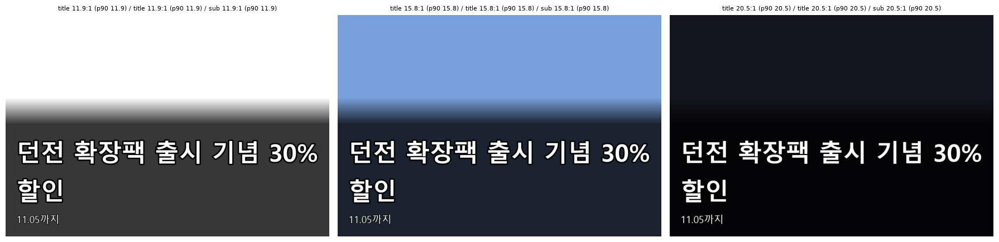

In [3]:
tests = [Image.new('RGB', (1216, 832), c) for c in [(255, 255, 255), (120, 160, 220), (20, 20, 30)]]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, im in zip(axes, tests):
    out, items = compose(im, EVENTS[2]['title'], EVENTS[2]['sub'])
    ax.imshow(out)
    ax.set_title(' / '.join(f"{i['kind']} {i['contrast_mean']:.1f}:1 (p90 {i['contrast_p90']:.1f})" for i in items), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 배너 생성

- 파이프라인을 한 번 불러 IP-Adapter를 붙이고, 게임마다 05에서 고른 강도로 생성한다.
- 생성 그림(`*_raw.png`)과 문구 합성 배너(`*.png`)를 따로 저장하고, 생성 시간과 대비를 `banner_records.csv`에 1장마다 저장한다. 다시 실행하면 이미 만든 배너는 건너뛴다.

In [4]:
import torch
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

pipe = StableDiffusionXLPipeline.from_pretrained(MODEL, torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(IPA['repo'], subfolder=IPA['subfolder'], weight_name=IPA['weight_name'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)

done = set(pd.read_csv(RECORDS_CSV).file) if RECORDS_CSV.exists() else set()
for ev in EVENTS:
    g = ev['game']
    ref = Image.open(REFS[g]).convert('RGB')
    pipe.set_ip_adapter_scale(SCALE[g])
    if LORA.get(g):
        pipe.load_lora_weights(LORA[g], weight_name='pytorch_lora_weights.safetensors', adapter_name='style')
    prompt = f"{GAME_TAGS[g]}, {ev['scene']}, {QUALITY}"
    for (w, h) in SIZES:
        for s in SEEDS:
            f = f'{g}_{w}x{h}_s{s}.png'
            if f in done:
                continue
            t0 = time.perf_counter()
            img = pipe(prompt=prompt, negative_prompt=NEGATIVE, ip_adapter_image=ref, width=w, height=h,
                       num_inference_steps=STEPS, guidance_scale=CFG, generator=torch.Generator('cpu').manual_seed(s)).images[0]
            gen_sec = round(time.perf_counter() - t0, 2)
            img.save(OUT_DIR / f.replace('.png', '_raw.png'))
            t0 = time.perf_counter()
            banner, items = compose(img, ev['title'], ev['sub'])
            text_sec = round(time.perf_counter() - t0, 3)
            banner.save(OUT_DIR / f)
            worst = min(items, key=lambda i: i['contrast_p90'] / i['need'])
            rec = dict(file=f, game=g, width=w, height=h, seed=s, ipa_scale=SCALE[g], lora=LORA.get(g) or '',
                       gen_sec=gen_sec, text_sec=text_sec,
                       title_contrast_mean=min(i['contrast_mean'] for i in items if i['kind'] == 'title'),
                       title_contrast_p90=min(i['contrast_p90'] for i in items if i['kind'] == 'title'),
                       sub_contrast_mean=min(i['contrast_mean'] for i in items if i['kind'] == 'sub'),
                       sub_contrast_p90=min(i['contrast_p90'] for i in items if i['kind'] == 'sub'),
                       wcag_pass_p90=all(i['contrast_p90'] >= i['need'] for i in items),
                       title_lines=sum(i['kind'] == 'title' for i in items), title_px=items[0]['size_px'])
            pd.DataFrame([rec]).to_csv(RECORDS_CSV, mode='a', header=not RECORDS_CSV.exists(), index=False, encoding='utf-8')
            done.add(f)
            print(f, f'{gen_sec}s', f"title {rec['title_contrast_p90']:.1f}:1 sub {rec['sub_contrast_p90']:.1f}:1", flush=True)
    if LORA.get(g):
        pipe.unload_lora_weights()

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1026 11:02:40.061000 16360 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1026 11:02:40.174000 16360 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading 

## 결과

,file,game,width,height,seed,ipa_scale,lora,gen_sec,text_sec,title_contrast_mean,title_contrast_p90,sub_contrast_mean,sub_contrast_p90,wcag_pass_p90,title_lines,title_px
0,nai_1216x832_s0.png,nai,1216,832,0,0.5,NaN,9.16,0.04,15.79,12.31,16.07,12.31,True,2,91
1,nai_1216x832_s1.png,nai,1216,832,1,0.5,NaN,8.87,0.04,14.03,12.48,14.23,12.49,True,2,91
2,nai_832x1216_s0.png,nai,832,1216,0,0.5,NaN,8.84,0.04,15.57,12.48,14.67,12.62,True,2,91
3,nai_832x1216_s1.png,nai,832,1216,1,0.5,NaN,8.80,0.04,15.98,13.01,13.92,12.66,True,2,91
4,kaykit_1216x832_s0.png,kaykit,1216,832,0,0.8,NaN,8.86,0.03,15.08,12.35,15.11,15.09,True,1,91
5,kaykit_1216x832_s1.png,kaykit,1216,832,1,0.8,NaN,8.68,0.03,15.21,14.28,14.57,14.28,True,1,91
6,kaykit_832x1216_s0.png,kaykit,832,1216,0,0.8,NaN,8.58,0.03,14.72,14.03,14.17,14.05,True,2,91
7,kaykit_832x1216_s1.png,kaykit,832,1216,1,0.8,NaN,8.61,0.03,15.58,14.38,14.46,14.38,True,2,91
8,x72_1216x832_s0.png,x72,1216,832,0,0.5,NaN,8.62,0.04,18.45,14.74,19.25,18.52,True,2,91
9,x72_1216x832_s1.png,x72,1216,832,1,0.5,NaN,8.76,0.04,19.43,18.48,19.82,19.10,True,2,91


장당 생성 시간 평균 8.79 초 | 문구 합성 평균 0.035 초
WCAG 대비 통과(밝은 쪽 10% 기준) 12 / 12


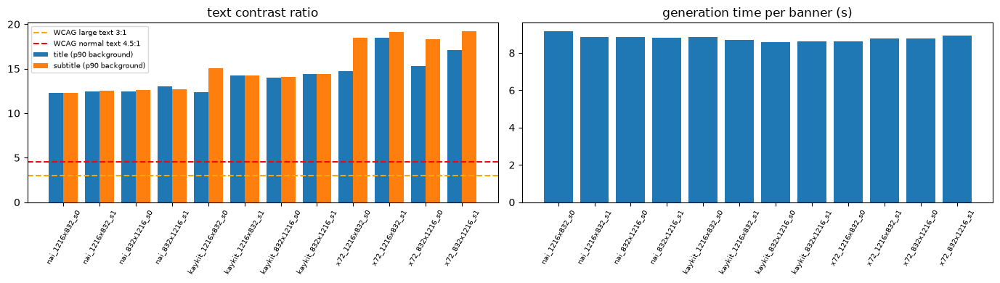

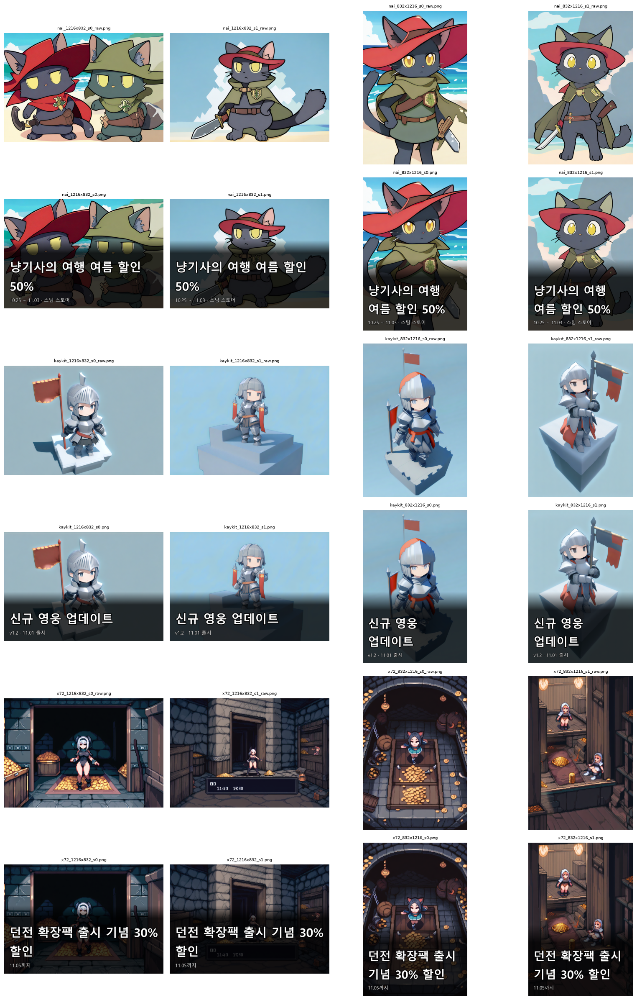

In [5]:
rec = pd.read_csv(RECORDS_CSV).drop_duplicates('file', keep='last')
display(rec.round(2))
print('장당 생성 시간 평균', round(rec.gen_sec.mean(), 2), '초 | 문구 합성 평균', round(rec.text_sec.mean(), 3), '초')
print('WCAG 대비 통과(밝은 쪽 10% 기준)', int(rec.wcag_pass_p90.sum()), '/', len(rec))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(rec))
axes[0].bar(x - 0.2, rec.title_contrast_p90, 0.4, label='title (p90 background)')
axes[0].bar(x + 0.2, rec.sub_contrast_p90, 0.4, label='subtitle (p90 background)')
axes[0].axhline(3.0, color='orange', linestyle='--', label='WCAG large text 3:1')
axes[0].axhline(4.5, color='red', linestyle='--', label='WCAG normal text 4.5:1')
axes[0].set_xticks(x, rec.file.str.replace('.png', ''), rotation=60, fontsize=7)
axes[0].set_title('text contrast ratio')
axes[0].legend(fontsize=7)
axes[1].bar(x, rec.gen_sec)
axes[1].set_xticks(x, rec.file.str.replace('.png', ''), rotation=60, fontsize=7)
axes[1].set_title('generation time per banner (s)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'banner_metrics.png', dpi=90)
plt.show()

# 배너 그리드: 행 = 이벤트, 열 = 크기 × seed (생성 그림 / 배너)
cols = [(w, h, s) for (w, h) in SIZES for s in SEEDS]
fig, axes = plt.subplots(len(EVENTS) * 2, len(cols), figsize=(4 * len(cols), 4 * 2 * len(EVENTS)), squeeze=False)
for r, ev in enumerate(EVENTS):
    for c, (w, h, s) in enumerate(cols):
        f = f"{ev['game']}_{w}x{h}_s{s}.png"
        for k, name in enumerate([f.replace('.png', '_raw.png'), f]):
            ax = axes[r * 2 + k, c]
            if (OUT_DIR / name).exists():
                ax.imshow(Image.open(OUT_DIR / name))
            ax.set_title(name, fontsize=7)
            ax.axis('off')
plt.tight_layout()
plt.savefig(OUT_DIR / 'banner_grid.png', dpi=70)
plt.show()

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (102 > 77). Running this sequence through the model will result in indexing errors
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer CLIPTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


model_max_length 77


,captions,tokens_mean,tokens_max,over_limit,last_tag_kept
caption,,,,,
nai,800,68.549,105,0.300,0.7
trigger,800,45.549,82,0.021,0.0


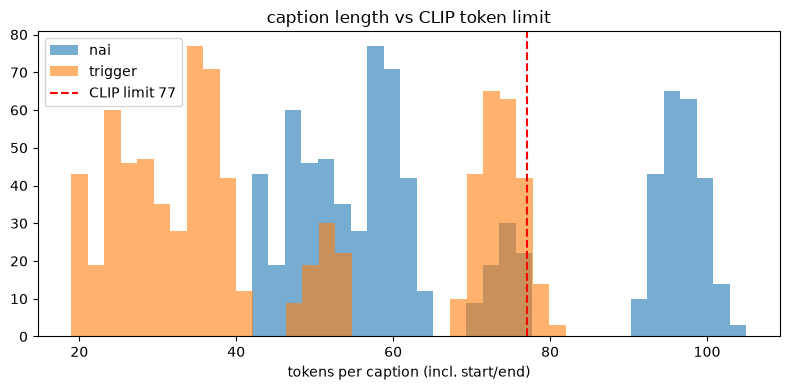

In [6]:
# SDXL 텍스트 인코더는 77토큰까지만 읽음(학습 스크립트 tokenize_captions도 truncation=True). 캡션 끝(그림체 태그·트리거 단어)이 잘렸는지 확인
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from transformers import CLIPTokenizer

tok = CLIPTokenizer.from_pretrained('cagliostrolab/animagine-xl-4.0', subfolder='tokenizer')
LIMIT = tok.model_max_length
rows = []
for kind in ['nai', 'trigger']:
    for line in open(Path('../data/processed/nai_lora') / kind / 'metadata.jsonl', encoding='utf-8'):
        text = json.loads(line)['text']
        n = len(tok(text).input_ids)
        tail = text.rsplit(', ', 1)[-1]
        kept = tok.decode(tok(text, truncation=True, max_length=LIMIT).input_ids, skip_special_tokens=True)
        rows.append({'caption': kind, 'tokens': n, 'over': n > LIMIT, 'tail_kept': tail.replace('_', ' ') in kept.replace('_', ' ')})
df = pd.DataFrame(rows)
print('model_max_length', LIMIT)
display(df.groupby('caption').agg(captions=('tokens', 'size'), tokens_mean=('tokens', 'mean'), tokens_max=('tokens', 'max'),
                                  over_limit=('over', 'mean'), last_tag_kept=('tail_kept', 'mean')).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for kind in ['nai', 'trigger']:
    ax.hist(df[df.caption == kind].tokens, bins=30, alpha=0.6, label=kind)
ax.axvline(LIMIT, color='red', linestyle='--', label=f'CLIP limit {LIMIT}')
ax.set_xlabel('tokens per caption (incl. start/end)')
ax.set_title('caption length vs CLIP token limit')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/lora_train/caption_tokens.png', dpi=90)
plt.show()

## 그림체 블록에만 IP-Adapter 적용 (10/22 수정)

- 전체 층에 IP-Adapter를 켜면 KayKit 배너 4장이 모두 단색 배경이 됐다(`outputs/banner/banner_grid.png`). 참조 이미지 `kk_0185`를 포함한 KayKit 렌더 520장이 단색 배경이고(`renders_index.csv`의 `bg` 열), IP-Adapter는 참조 이미지의 내용까지 따라가기 때문이다(IP-Adapter 논문 5절 "resemble the reference images in content and style").
- diffusers 공식 IP-Adapter 문서 "Style and layout control"(InstantStyle)대로 그림체 블록(up `block_0`)에만 IP-Adapter를 켜고, 구도와 내용은 프롬프트가 정하게 한다. 값 1.0은 문서 예시값이다.
- 나머지 조건(이벤트, 크기, seed, 생성 설정, 문구 합성)은 위와 같다. 결과는 `outputs/banner_style_only/`에 저장한다.
- 두 방식을 수치로도 비교한다. 05와 같은 CLIP(`openai/clip-vit-base-patch32`)으로
  - `style_sim`: 생성 그림과 같은 게임 이미지 100장(참조 이미지 제외, seed 0 무작위)의 평균 코사인 유사도
  - `scene_sim`: 생성 그림과 장면 요청 문구(`scene`)의 코사인 유사도
- 실행 순서: "설정" → "문구 합성 함수" → 이 섹션의 셀

In [7]:
import torch
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

OLD_DIR = ROOT / 'outputs' / 'banner'
NEW_DIR = ROOT / 'outputs' / 'banner_style_only'
NEW_DIR.mkdir(parents=True, exist_ok=True)
NEW_CSV = NEW_DIR / 'banner_records.csv'
# diffusers IP-Adapter 문서 "Style and layout control"의 그림체 블록만 켜는 설정(문서 예시값)
IPA_SCALE_STYLE_ONLY = {'up': {'block_0': [0.0, 1.0, 0.0]}}

if 'pipe' not in globals():
    pipe = StableDiffusionXLPipeline.from_pretrained(MODEL, torch_dtype=torch.bfloat16)
    pipe.load_ip_adapter(IPA['repo'], subfolder=IPA['subfolder'], weight_name=IPA['weight_name'])
    pipe.to('cuda')
    pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
pipe.set_ip_adapter_scale(IPA_SCALE_STYLE_ONLY)

done = set(pd.read_csv(NEW_CSV).file) if NEW_CSV.exists() else set()
for ev in EVENTS:
    g = ev['game']
    ref = Image.open(REFS[g]).convert('RGB')
    if LORA.get(g):
        pipe.load_lora_weights(LORA[g], weight_name='pytorch_lora_weights.safetensors', adapter_name='style')
    prompt = f"{GAME_TAGS[g]}, {ev['scene']}, {QUALITY}"
    for (w, h) in SIZES:
        for s in SEEDS:
            f = f'{g}_{w}x{h}_s{s}.png'
            if f in done:
                continue
            t0 = time.perf_counter()
            img = pipe(prompt=prompt, negative_prompt=NEGATIVE, ip_adapter_image=ref, width=w, height=h,
                       num_inference_steps=STEPS, guidance_scale=CFG, generator=torch.Generator('cpu').manual_seed(s)).images[0]
            gen_sec = round(time.perf_counter() - t0, 2)
            img.save(NEW_DIR / f.replace('.png', '_raw.png'))
            banner, items = compose(img, ev['title'], ev['sub'])
            banner.save(NEW_DIR / f)
            rec = dict(file=f, game=g, width=w, height=h, seed=s, ipa_scale='style_only up.block_0=1.0', lora=LORA.get(g) or '',
                       gen_sec=gen_sec,
                       title_contrast_p90=min(i['contrast_p90'] for i in items if i['kind'] == 'title'),
                       sub_contrast_p90=min(i['contrast_p90'] for i in items if i['kind'] == 'sub'),
                       wcag_pass_p90=all(i['contrast_p90'] >= i['need'] for i in items))
            pd.DataFrame([rec]).to_csv(NEW_CSV, mode='a', header=not NEW_CSV.exists(), index=False, encoding='utf-8')
            done.add(f)
            print(f, f'{gen_sec}s', flush=True)
    if LORA.get(g):
        pipe.unload_lora_weights()

### 두 방식 비교 (점수)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 22783.31it/s]


style_sim         scene_sim        
                             mean     std      mean     std
game   mode                                                
nai    all layers          0.7147  0.0186    0.1793  0.0213
kaykit all layers          0.7460  0.0273    0.2183  0.0118
x72    all layers          0.7153  0.0478    0.2770  0.0257
nai    style block only    0.6964  0.0166    0.1898  0.0142
kaykit style block only    0.6477  0.0456    0.2320  0.0232
x72    style block only    0.6671  0.0974    0.3012  0.0174

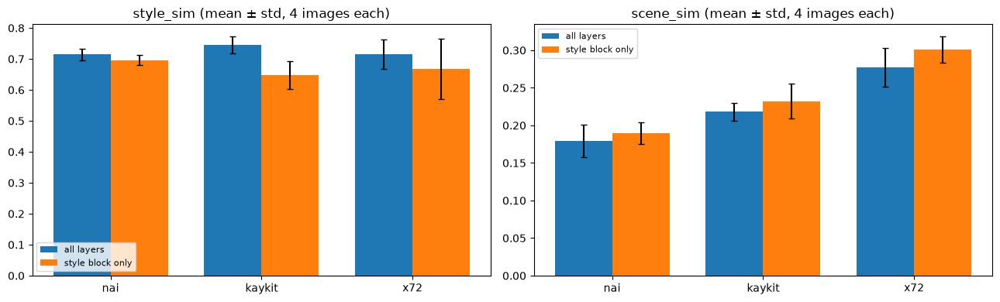

In [8]:
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


@torch.no_grad()
def embed_images(paths, bs=16):
    out = []
    for i in range(0, len(paths), bs):
        x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
        out.append(torch.nn.functional.normalize(feat(clip.get_image_features(**x)), dim=-1).float().cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def embed_texts(texts):
    t = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to('cuda')
    return torch.nn.functional.normalize(feat(clip.get_text_features(**t)), dim=-1).float().cpu().numpy()


GAME_FILES = {'nai': sorted((RAW / 'nai' / 'lora_gen').glob('*.png')),
              'kaykit': sorted((RAW / 'kaykit' / 'renders').glob('kk_*.png')),
              'x72': sorted((RAW / 'pixel_0x72' / 'scenes').glob('x72_scene_*.png'))}
rng = np.random.default_rng(0)
HELD = {}
for g, fs in GAME_FILES.items():
    pool = [p for p in fs if p.name != REFS[g].name]
    HELD[g] = embed_images([pool[i] for i in rng.choice(len(pool), 100, replace=False)])
SCENE = {ev['game']: embed_texts([ev['scene']])[0] for ev in EVENTS}

rows = []
for d, mode in [(OLD_DIR, 'all layers'), (NEW_DIR, 'style block only')]:
    for ev in EVENTS:
        g = ev['game']
        for (w, h) in SIZES:
            for s in SEEDS:
                f = d / f'{g}_{w}x{h}_s{s}_raw.png'
                if f.exists():
                    rows.append(dict(mode=mode, game=g, file=f.name, path=f))
cmp = pd.DataFrame(rows)
E = embed_images(list(cmp.path))
cmp['style_sim'] = [float((HELD[g] @ e).mean()) for e, g in zip(E, cmp.game)]
cmp['scene_sim'] = [float(SCENE[g] @ e) for e, g in zip(E, cmp.game)]
cmp.drop(columns='path').to_csv(NEW_DIR / 'compare_scores.csv', index=False, encoding='utf-8-sig')
summ = cmp.groupby(['game', 'mode'], sort=False)[['style_sim', 'scene_sim']].agg(['mean', 'std']).round(4)
display(summ)

games = list(GAME_FILES)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ['style_sim', 'scene_sim']):
    for k, mode in enumerate(['all layers', 'style block only']):
        s = cmp[cmp['mode'] == mode].groupby('game')[col].agg(['mean', 'std']).reindex(games)
        ax.bar(np.arange(len(games)) + (k - 0.5) * 0.38, s['mean'], 0.38, yerr=s['std'], capsize=3, label=mode)
    ax.set_xticks(np.arange(len(games)), games)
    ax.set_title(f'{col} (mean ± std, 4 images each)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(NEW_DIR / 'compare_scores.png', dpi=90)
plt.show()

### 두 방식 비교 (그림)

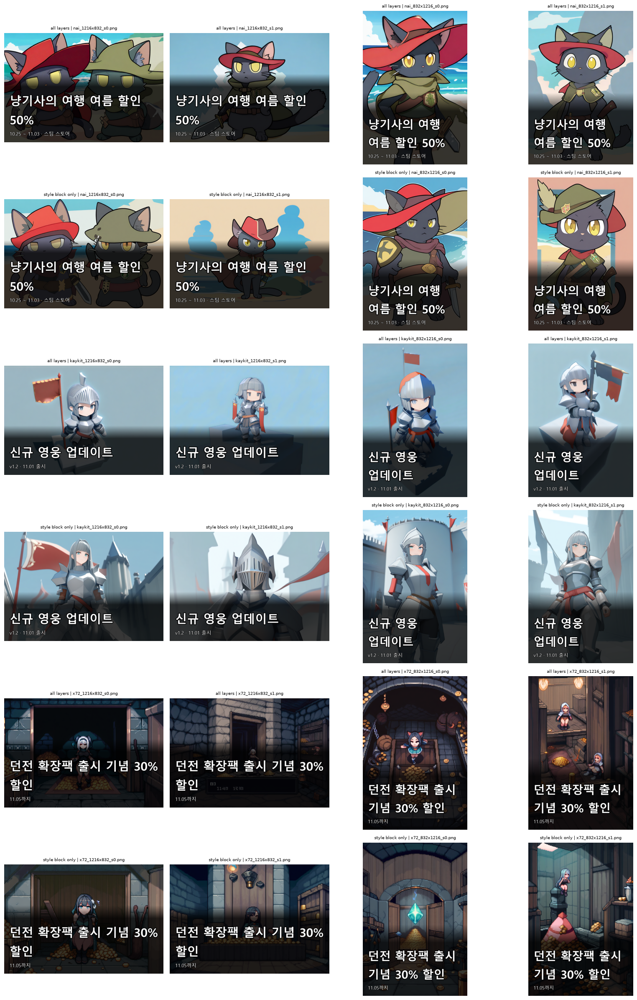

In [9]:
cols = [(w, h, s) for (w, h) in SIZES for s in SEEDS]
fig, axes = plt.subplots(len(EVENTS) * 2, len(cols), figsize=(4 * len(cols), 8 * len(EVENTS)), squeeze=False)
for r, ev in enumerate(EVENTS):
    for c, (w, h, s) in enumerate(cols):
        f = f"{ev['game']}_{w}x{h}_s{s}.png"
        for k, (d, tag) in enumerate([(OLD_DIR, 'all layers'), (NEW_DIR, 'style block only')]):
            ax = axes[r * 2 + k, c]
            if (d / f).exists():
                ax.imshow(Image.open(d / f))
            ax.set_title(f'{tag} | {f}', fontsize=7)
            ax.axis('off')
plt.tight_layout()
plt.savefig(NEW_DIR / 'compare_grid.png', dpi=70)
plt.show()

## 한국어 요청 → 배너 (Qwen3-VL-8B 연결, 10/23)

사용자가 한국어로 배너를 요청하면 Qwen3-VL-8B가 영어 장면 태그·제목·부제로 바꾸고, 그 결과로 위와 같은 방식(animagine_xl4 + IP-Adapter 그림 생성 → Pillow 문구 합성)으로 배너를 만든다.

- 요청·지시문: 08 "설정"의 기능 B 요청 6개(`B_REQUESTS`)와 지시문(`SYSTEM_B`, `INSTRUCTION_B`)을 그대로 쓴다. 08 비교에서 Qwen은 이 6건의 모든 지표가 1.00이었다(`summary_B.csv`).
- Qwen 최대 VRAM 16.8GB(08) + 배너 파이프라인 13.07GB(05) > 24GB라 두 모델을 동시에 올릴 수 없다. 그래서 차례로 실행하고 단계마다 시간과 VRAM을 잰다.
  1. 노트북에 올라와 있는 배너 파이프라인·CLIP을 내림
  2. Qwen을 별도 프로세스에서 로드 → 6건 변환 → 프로세스 종료(VRAM 반환)
  3. 배너 파이프라인 다시 로드 → 6건 생성 + 문구 합성
- IP-Adapter 적용 방식은 아직 정하지 않아(전체 층 vs 그림체 블록만) 두 방식으로 모두 만든다.
- 크기는 가로형 1216×832, seed 0 한 장씩이다. 세로형·seed 1은 위 섹션에서 이미 확인했고, 이 섹션은 연결과 시간 측정이 목적이라 장수를 줄였다.
- 결과: `outputs/banner_request/` (`request_records.csv`, `banner_records.csv`, `sequence_timing.csv`, 그리드·그래프)
- 실행 순서: "설정" → "문구 합성 함수" → 이 섹션

In [10]:
import gc
import json
import os
import re
import subprocess
import sys

REQ_DIR = ROOT / 'outputs' / 'banner_request'
REQ_DIR.mkdir(parents=True, exist_ok=True)
REQ_CSV = REQ_DIR / 'request_records.csv'
REQ_BANNER_CSV = REQ_DIR / 'banner_records.csv'
TIMING_CSV = REQ_DIR / 'sequence_timing.csv'
QWEN_REPO = 'Qwen/Qwen3-VL-8B-Instruct'
MAX_NEW_TOKENS = 512

# 08 "설정"과 같은 게임 정보·요청·지시문
GAME_INFO = {'nai': '냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임',
             'x72': '픽셀 아트 던전 탐험 게임',
             'kaykit': '로우폴리 3D 판타지 어드벤처 게임'}
B_REQUESTS = [
    ('nai', '여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.'),
    ('nai', '할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘'),
    ('kaykit', '성 앞마당에서 기사가 깃발 든 느낌으로 신규 영웅 업데이트 배너, 버전 1.2, 11월 1일 출시'),
    ('kaykit', '눈 내리는 겨울 마을 배경으로 겨울 이벤트 배너 만들어줘, 30% 할인'),
    ('x72', '금화가 가득한 보물방 배경으로 던전 확장팩 출시 기념 30% 할인 배너, 11월 5일까지'),
    ('x72', '용암 던전 배경으로 보스 레이드 이벤트 배너 만들어줘'),
]
SYSTEM_B = '너는 게임 이벤트 배너 제작을 돕는 도우미다.'
INSTRUCTION_B = """게임 정보: {info}
요청: {request}

요청을 읽고 이미지 생성용 영어 장면 태그와 배너 문구를 만들어줘.
- scene: 배경과 장면을 묘사하는 영어 태그 5~10개, 쉼표로 구분. 글자·텍스트·로고 관련 태그는 넣지 마.
- title: 배너 제목, 한국어, 20자 이내
- sub: 기간·조건 등 부제, 한국어
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"scene": "tag1, tag2", "title": "제목", "sub": "부제"}}"""
REQ_TASKS = [dict(item=f'B{i}', game=g, request=r, system=SYSTEM_B,
                  prompt=INSTRUCTION_B.format(info=GAME_INFO[g], request=r)) for i, (g, r) in enumerate(B_REQUESTS)]
IPA_MODES = {'all_layers': None, 'style_only': {'up': {'block_0': [0.0, 1.0, 0.0]}}}
REQ_SIZE, REQ_SEED = (1216, 832), 0
print(len(REQ_TASKS), 'requests')

6 requests


In [11]:
# 1. 노트북에 올라와 있는 GPU 모델을 내림 (Qwen 16.8GB + 배너 13.07GB > 24GB)
import torch

for _name in ['pipe', 'clip']:
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()
free, total = torch.cuda.mem_get_info()
print(f'GPU 남은 메모리 {free / 1024**3:.2f} / {total / 1024**3:.1f} GB')

# 2. Qwen 별도 프로세스: 로드 → 6건 변환 → 종료
CHILD_REQ = r"""
import json, sys, time
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 2)
torch.cuda.reset_peak_memory_stats()
out_rows = []
for t in a['tasks']:
    messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                {'role': 'user', 'content': [{'type': 'text', 'text': t['prompt']}]}]
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    t1 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], do_sample=False)
    n_in = inputs['input_ids'].shape[1]
    text = proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
    out_rows.append(dict(item=t['item'], sec=round(time.perf_counter() - t1, 2), text=text))
print('RESULT' + json.dumps(dict(load_sec=load_sec, peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2),
                                 rows=out_rows), ensure_ascii=False), flush=True)
"""

t_qwen = time.perf_counter()
p = subprocess.run([sys.executable, '-c', CHILD_REQ], input=json.dumps(dict(repo=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, tasks=REQ_TASKS)),
                   capture_output=True, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
qwen_total = round(time.perf_counter() - t_qwen, 2)
if p.returncode != 0 or 'RESULT' not in p.stdout:
    print(p.stdout[-1500:], p.stderr[-2000:])
    raise RuntimeError('Qwen 단계 실패')
qres = json.loads(p.stdout.split('RESULT', 1)[1].strip().splitlines()[0])


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


rows = []
for t, r in zip(REQ_TASKS, qres['rows']):
    d = parse_json(r['text']) or {}
    ok = all(isinstance(d.get(k), str) for k in ['scene', 'title', 'sub'])
    nums = re.findall(r'\d+(?:\.\d+)?', t['request'])
    tags = [x.strip() for x in d.get('scene', '').split(',') if x.strip()] if ok else []
    rows.append(dict(item=t['item'], game=t['game'], request=t['request'], sec=r['sec'], json_ok=ok,
                     scene=d.get('scene', ''), title=d.get('title', ''), sub=d.get('sub', ''),
                     tags_ok=5 <= len(tags) <= 10, title_ok=ok and len(d['title']) <= 20,
                     numbers_kept=np.mean([n in d.get('title', '') + ' ' + d.get('sub', '') for n in nums]) if nums and ok else np.nan,
                     raw=r['text']))
req = pd.DataFrame(rows)
req.to_csv(REQ_CSV, index=False, encoding='utf-8-sig')
pd.set_option('display.max_colwidth', 200)
display(req[['item', 'game', 'request', 'scene', 'title', 'sub', 'json_ok', 'tags_ok', 'title_ok', 'numbers_kept', 'sec']])
free_after, _ = torch.cuda.mem_get_info()
print(f"Qwen 로드 {qres['load_sec']}초 | 변환 {req.sec.sum():.2f}초(6건) | 최대 VRAM {qres['peak_vram_gb']}GB | 프로세스 전체 {qwen_total}초")
print(f'Qwen 종료 후 GPU 남은 메모리 {free_after / 1024**3:.2f} GB')

GPU 남은 메모리 22.71 / 24.0 GB


,item,game,request,scene,title,sub,json_ok,tags_ok,title_ok,numbers_kept,sec
0,B0,nai,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,"summer beach, sunset ocean, palm trees, sandy shore, gentle waves",냥기사의 여행 50% 할인,10월 25일 ~ 11월 3일,True,True,True,1.0,4.67
1,B1,nai,"할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘","dark forest, moonlight, autumn leaves, spooky trees, glowing eyes, misty atmosphere",할로윈 의상 업데이트,10.27~11.3까지 한정 적용,True,True,True,NaN,4.39
2,B2,kaykit,"성 앞마당에서 기사가 깃발 든 느낌으로 신규 영웅 업데이트 배너, 버전 1.2, 11월 1일 출시","castle courtyard, knight standing, flag waving, medieval fantasy, sunny day, stone architecture","신규 영웅, 영웅의 출현!","버전 1.2, 11월 1일 출시",True,True,True,1.0,4.60
3,B3,kaykit,"눈 내리는 겨울 마을 배경으로 겨울 이벤트 배너 만들어줘, 30% 할인","snowy village, winter trees, glowing lanterns, frozen river, cozy cabin, falling snow, misty atmosphere, soft light, quiet streets",겨울 마을 특가 이벤트,30% 할인 중,True,True,True,1.0,4.55
4,B4,x72,"금화가 가득한 보물방 배경으로 던전 확장팩 출시 기념 30% 할인 배너, 11월 5일까지","pixel dungeon, treasure room, gold coins, glowing gems, ancient stone walls, torchlight, cracked floor, mystical atmosphere, fantasy adventure",보물방 열려요!,11월 5일까지 30% 할인,True,True,True,1.0,4.67
5,B5,x72,용암 던전 배경으로 보스 레이드 이벤트 배너 만들어줘,"volcanic dungeon, lava rivers, fiery cavern, glowing magma, stone pillars, dungeon entrance, dark fantasy, pixel art",용암 던전 보스 레이드,지금 바로 시작!,True,True,True,NaN,4.40


Qwen 로드 16.15초 | 변환 27.28초(6건) | 최대 VRAM 16.4GB | 프로세스 전체 62.64초
Qwen 종료 후 GPU 남은 메모리 22.71 GB


In [12]:
# 3. 배너 파이프라인 다시 로드 → 6건 × IP-Adapter 방식 2개 생성 + 문구 합성
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
pipe = StableDiffusionXLPipeline.from_pretrained(MODEL, torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(IPA['repo'], subfolder=IPA['subfolder'], weight_name=IPA['weight_name'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
pipe_load = round(time.perf_counter() - t0, 2)

brecs = []
w, h = REQ_SIZE
for r in req.itertuples():
    if not r.json_ok:
        print(r.item, 'JSON 실패 → 건너뜀')
        continue
    ref = Image.open(REFS[r.game]).convert('RGB')
    prompt = f'{GAME_TAGS[r.game]}, {r.scene}, {QUALITY}'
    for mode, scale in IPA_MODES.items():
        pipe.set_ip_adapter_scale(SCALE[r.game] if scale is None else scale)
        t1 = time.perf_counter()
        img = pipe(prompt=prompt, negative_prompt=NEGATIVE, ip_adapter_image=ref, width=w, height=h,
                   num_inference_steps=STEPS, guidance_scale=CFG, generator=torch.Generator('cpu').manual_seed(REQ_SEED)).images[0]
        gen_sec = round(time.perf_counter() - t1, 2)
        f = f'{r.item}_{r.game}_{mode}.png'
        img.save(REQ_DIR / f.replace('.png', '_raw.png'))
        t1 = time.perf_counter()
        banner, items = compose(img, r.title, r.sub)
        text_sec = round(time.perf_counter() - t1, 3)
        banner.save(REQ_DIR / f)
        brecs.append(dict(file=f, item=r.item, game=r.game, mode=mode, gen_sec=gen_sec, text_sec=text_sec,
                          title_contrast_p90=min(i['contrast_p90'] for i in items if i['kind'] == 'title'),
                          sub_contrast_p90=min(i['contrast_p90'] for i in items if i['kind'] == 'sub'),
                          wcag_pass_p90=all(i['contrast_p90'] >= i['need'] for i in items)))
        print(f, f'{gen_sec}s', flush=True)
banner_peak = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
brec = pd.DataFrame(brecs)
brec.to_csv(REQ_BANNER_CSV, index=False, encoding='utf-8-sig')

timing = pd.DataFrame([
    dict(step='Qwen load', sec=qres['load_sec'], peak_vram_gb=qres['peak_vram_gb']),
    dict(step='Qwen convert (6 requests)', sec=round(req.sec.sum(), 2), peak_vram_gb=qres['peak_vram_gb']),
    dict(step='banner pipeline load', sec=pipe_load, peak_vram_gb=banner_peak),
    dict(step=f'banner generate ({len(brec)} images)', sec=round(brec.gen_sec.sum(), 2), peak_vram_gb=banner_peak),
    dict(step=f'text compose ({len(brec)} images)', sec=round(brec.text_sec.sum(), 2), peak_vram_gb=np.nan),
])
timing.to_csv(TIMING_CSV, index=False, encoding='utf-8-sig')
display(timing)
display(brec.round(2))
per_request = (qres['load_sec'] + pipe_load) / len(req) + req.sec.mean() + brec.groupby('item').gen_sec.mean().mean()
print(f'요청 1건당 (모델 로드 2번을 6건에 나눔 + 변환 1건 + 배너 1장): 약 {per_request:.1f}초')
print('WCAG 대비 통과(밝은 쪽 10% 기준)', int(brec.wcag_pass_p90.sum()), '/', len(brec))

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading weights: 100%|██████████| 776/776 [00:03<00:00, 205.90it/s]
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (96 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['ocean , palm trees , sandy shore , gentle waves , masterpiece , high score , great score , absurdres']
[transformers] Token i

B0_nai_all_layers.png 10.63s


The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['ocean , palm trees , sandy shore , gentle waves , masterpiece , high score , great score , absurdres']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['ocean , palm trees , sandy shore , gentle waves , masterpiece , high score , great score , absurdres']
100%|██████████| 28/28 [00:09<00:00,  2.88it/s]


B0_nai_style_only.png 10.23s


The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: [', autumn leaves , spooky trees , glowing eyes , misty atmosphere , masterpiece , high score , great score , absurdres']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: [', autumn leaves , spooky trees , glowing eyes , misty atmosphere , masterpiece , high score , great score , absurdres']
100%|██████████| 28/28 [00:09<00:00,  2.82it/s]


B1_nai_all_layers.png 10.44s


... (17 outputs left out)

B5_x72_style_only.png 10.46s


,step,sec,peak_vram_gb
0,Qwen load,16.15,16.40
1,Qwen convert (6 requests),27.28,16.40
2,banner pipeline load,14.25,12.99
3,banner generate (12 images),125.66,12.99
4,text compose (12 images),0.39,NaN


,file,item,game,mode,gen_sec,text_sec,title_contrast_p90,sub_contrast_p90,wcag_pass_p90
0,B0_nai_all_layers.png,B0,nai,all_layers,10.63,0.04,13.37,12.79,True
1,B0_nai_style_only.png,B0,nai,style_only,10.23,0.04,13.80,13.80,True
2,B1_nai_all_layers.png,B1,nai,all_layers,10.44,0.03,13.02,13.57,True
3,B1_nai_style_only.png,B1,nai,style_only,10.30,0.03,12.45,14.13,True
4,B2_kaykit_all_layers.png,B2,kaykit,all_layers,10.53,0.04,11.98,11.94,True
5,B2_kaykit_style_only.png,B2,kaykit,style_only,10.31,0.03,12.29,12.45,True
6,B3_kaykit_all_layers.png,B3,kaykit,all_layers,10.58,0.03,12.09,12.85,True
7,B3_kaykit_style_only.png,B3,kaykit,style_only,10.29,0.03,12.32,13.16,True
8,B4_x72_all_layers.png,B4,x72,all_layers,10.53,0.03,17.31,13.59,True
9,B4_x72_style_only.png,B4,x72,style_only,10.40,0.03,17.21,13.30,True


요청 1건당 (모델 로드 2번을 6건에 나눔 + 변환 1건 + 배너 1장): 약 20.1초
WCAG 대비 통과(밝은 쪽 10% 기준) 12 / 12


### 요청별 배너와 단계별 시간·VRAM

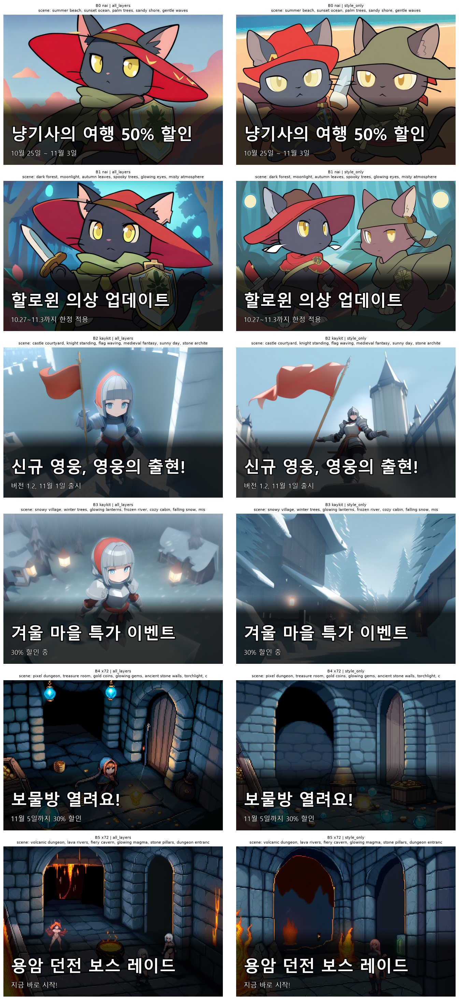

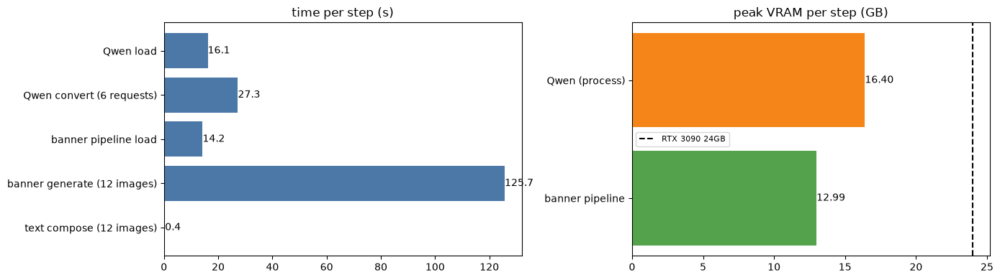

In [13]:
modes = list(IPA_MODES)
items_ok = [r for r in req.itertuples() if r.json_ok]
fig, axes = plt.subplots(len(items_ok), len(modes), figsize=(7 * len(modes), 4.9 * len(items_ok)), squeeze=False)
for i, r in enumerate(items_ok):
    for j, mode in enumerate(modes):
        ax = axes[i, j]
        f = REQ_DIR / f'{r.item}_{r.game}_{mode}.png'
        if f.exists():
            ax.imshow(Image.open(f))
        ax.set_title(f'{r.item} {r.game} | {mode}\nscene: {r.scene[:90]}', fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.savefig(REQ_DIR / 'request_banner_grid.png', dpi=60)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(timing.step, timing.sec, color='#4C78A8')
axes[0].bar_label(axes[0].containers[0], fmt='%.1f')
axes[0].invert_yaxis()
axes[0].set_title('time per step (s)')
v = timing.dropna(subset=['peak_vram_gb']).drop_duplicates('peak_vram_gb')
axes[1].barh(['Qwen (process)', 'banner pipeline'][:len(v)], v.peak_vram_gb, color=['#F58518', '#54A24B'][:len(v)])
axes[1].bar_label(axes[1].containers[0], fmt='%.2f')
axes[1].axvline(24, color='black', linestyle='--', label='RTX 3090 24GB')
axes[1].invert_yaxis()
axes[1].legend(fontsize=8)
axes[1].set_title('peak VRAM per step (GB)')
plt.tight_layout()
plt.savefig(REQ_DIR / 'sequence_timing.png', dpi=90)
plt.show()

## 배너 문제 수정 실험 (10/23)

위 "한국어 요청 → 배너" 결과에서 나온 문제를 고치는 후보를 모두 같은 조건으로 생성해 비교한다. 결과는 `outputs/banner_fix/`에 저장하고, 위 섹션 결과(`outputs/banner_request/`)는 문제 사례로 그대로 둔다.

| 실험 | 문제 | 후보 |
|---|---|---|
| R | Qwen이 요청에 없는 날짜(B1 "10.27\~11.3")·판촉 표현(B3 "특가")을 지어냄 | 기능 A와 같은 판촉 금지 규칙을 지시문에 넣고 코드로 검증, 실패하면 (나) 후보 여러 개 방식으로 재생성(10/23 기능 A 결정과 같은 방식) |
| T | 냥기사 프롬프트가 CLIP 77토큰을 넘어 장면 태그·품질 태그가 잘림(셀 출력 "truncated because CLIP can only handle sequences up to 77 tokens") | 지금 방식 / (가) 장면 태그를 맨 앞 / (나) 냥기사 태그 줄이기 / (다) Compel로 자르지 않고 처리 |
| N | 냥기사 그림체 블록 방식에서 고양이가 두 마리 | (a) 맨 앞에 `solo`, 부정 프롬프트에 중복 태그 / (b) 그림체 + 구도 블록 |
| K | KayKit 전체 층 방식이 애니풍 소녀 기사 | (a) 그림체 블록 + `3d, low poly, render`를 앞에, 부정에 `anime, 1girl` / (b) 그림체 블록 강도 1.5 / (c) KayKit만 sdxl\_base |
| X | 0x72 용암이 거의 안 보임 | (a) 장면 태그를 맨 앞 / (b) Compel 가중치로 장면 태그 강조 `(장면)1.3` / (c) 전체 층 강도 0.3 |

- 후보 근거
  - 프롬프트 순서·수 태그: Animagine XL 4.0 모델 카드 프롬프트 형식 "1girl/1boy/1other, character, series, rating, everything else, quality tags"(수 태그가 맨 앞)
  - Compel: 77토큰보다 긴 프롬프트를 나눠 처리하고 `(텍스트)가중치` 문법으로 강조한다(compel README). 2.4.0이 transformers 5를 지원한다. Animagine 모델 카드도 긴 프롬프트용으로 `lpw_stable_diffusion_xl` 파이프라인을 예시로 든다.
  - 그림체 + 구도 블록: diffusers IP-Adapter 문서 "Style and layout control" 예시값 `{'down': {'block_2': [0.0, 1.0]}, 'up': {'block_0': [0.0, 1.0, 0.0]}}`
  - sdxl\_base: 05에서 KayKit style\_sim이 animagine\_xl4보다 높았다(0.804 vs 0.783). 강도는 05에서 sdxl\_base KayKit style\_sim이 가장 높았던 값을 쓴다.
  - 강도 1.5(K-b)와 0.3(X-c), 가중치 1.3(X-b)은 근거 문서가 없는 탐색값이다. 효과가 있으면 값을 더 나눠 다시 본다.
- 공통 조건: 위 섹션과 같은 생성 설정(Euler a, 28스텝, CFG 5), 1216×832, seed 0·1. 장면 태그는 위 섹션 Qwen 결과(`banner_request/request_records.csv`)를 그대로 써서 T·N·K·X는 프롬프트 조건만 바꾼다.
- 지표 (앞 섹션과 같은 CLIP `openai/clip-vit-base-patch32`)
  - `style_sim`: 같은 게임 이미지 100장(참조 이미지 제외, seed 0 무작위)과의 평균 코사인 유사도
  - `scene_sim`: 장면 태그 문장과의 코사인 유사도
  - `two_cat_prob`(냥기사): CLIP 제로샷으로 "one black cat"과 "two black cats" 중 두 마리 쪽 확률
  - `n_tokens`, `truncated`: CLIP 토크나이저 기준 프롬프트 길이와 77토큰 초과 여부
- 규모: R 변환 6건 + 배너 12장, 실험 이미지 92장(장당 약 9초). KayKit (c)는 sdxl\_base를 받아야 한다(05 기록 13.24GB, 117.9초).
- 실행 순서: "설정" → "문구 합성 함수" → 이 섹션

In [14]:
# 실험 T·X의 (다)·(b)용. compel 2.4.0이 transformers 5 지원(compel README). 실험 전용, 채택하지 않으면 제거
%pip install compel==2.4.0

Note: you may need to restart the kernel to use updated packages.


In [15]:
import gc
import json
import os
import re
import subprocess
import sys

import torch

FIX_DIR = ROOT / 'outputs' / 'banner_fix'
FIX_DIR.mkdir(parents=True, exist_ok=True)
R_CSV = FIX_DIR / 'rules_requests.csv'
R_BANNER_CSV = FIX_DIR / 'rules_banners.csv'
EXP_CSV = FIX_DIR / 'exp_records.csv'
QWEN_REPO = 'Qwen/Qwen3-VL-8B-Instruct'
SDXL_BASE = 'stabilityai/stable-diffusion-xl-base-1.0'
MAX_NEW_TOKENS = 512
W, H = 1216, 832
FIX_SEEDS = [0, 1]

# 위 "한국어 요청 → 배너" 설정과 같은 게임 정보·요청·지시문 (이 섹션만 따로 실행할 수 있게 다시 정의)
GAME_INFO = {'nai': '냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임',
             'x72': '픽셀 아트 던전 탐험 게임',
             'kaykit': '로우폴리 3D 판타지 어드벤처 게임'}
B_REQUESTS = [
    ('nai', '여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.'),
    ('nai', '할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘'),
    ('kaykit', '성 앞마당에서 기사가 깃발 든 느낌으로 신규 영웅 업데이트 배너, 버전 1.2, 11월 1일 출시'),
    ('kaykit', '눈 내리는 겨울 마을 배경으로 겨울 이벤트 배너 만들어줘, 30% 할인'),
    ('x72', '금화가 가득한 보물방 배경으로 던전 확장팩 출시 기념 30% 할인 배너, 11월 5일까지'),
    ('x72', '용암 던전 배경으로 보스 레이드 이벤트 배너 만들어줘'),
]
SYSTEM_B = '너는 게임 이벤트 배너 제작을 돕는 도우미다.'
# 기능 A 문구 규칙의 금지 ①(판촉 표현)과 같은 단어 목록
BANNED_PROMO = ['할인', '특가', '무료', '이벤트', '출시', '사전예약', '선물']
INSTRUCTION_B2 = """게임 정보: {info}
요청: {request}

요청을 읽고 이미지 생성용 영어 장면 태그와 배너 문구를 만들어줘.
- scene: 배경과 장면을 묘사하는 영어 태그 5~10개, 쉼표로 구분. 글자·텍스트·로고 관련 태그는 넣지 마.
- title: 배너 제목, 한국어, 20자 이내
- sub: 기간·조건 등 부제, 한국어
규칙
1. 요청에 있는 숫자(할인율·날짜·버전)는 글자 그대로 넣고, 요청에 없는 날짜·기간·가격·숫자는 지어내지 마.
2. 요청에 없는 판촉 표현은 쓰지 마: {banned}
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"scene": "tag1, tag2", "title": "제목", "sub": "부제"}}"""
R_TASKS = [dict(item=f'B{i}', game=g, request=r, system=SYSTEM_B,
                prompt=INSTRUCTION_B2.format(info=GAME_INFO[g], request=r, banned=', '.join(BANNED_PROMO)))
           for i, (g, r) in enumerate(B_REQUESTS)]

VALIDATOR_B = r"""
import json, re


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def check_b(text, request, banned):
    d = parse_json(text)
    if not (d and all(isinstance(d.get(k), str) for k in ['scene', 'title', 'sub'])):
        return ['JSON 형식이 아니다. {"scene": "...", "title": "...", "sub": "..."} 형식으로만 써야 한다.']
    probs = []
    tags = [x.strip() for x in d['scene'].split(',') if x.strip()]
    if not 5 <= len(tags) <= 10:
        probs.append(f'scene 태그는 5~10개여야 하는데 {len(tags)}개다.')
    if len(d['title']) > 20:
        probs.append(f'title은 20자 이내여야 하는데 {len(d["title"])}자다.')
    copy = d['title'] + ' ' + d['sub']
    req_nums = re.findall(r'\d+(?:\.\d+)?', request)
    missing = [n for n in req_nums if n not in copy]
    if missing:
        probs.append(f'요청에 있는 숫자가 빠졌다: {", ".join(missing)}')
    extra = [n for n in re.findall(r'\d+(?:\.\d+)?', copy) if n not in req_nums]
    if extra:
        probs.append(f'요청에 없는 숫자를 지어냈다: {", ".join(extra)}')
    words = [w for w in banned if w in copy and w not in request]
    if words:
        probs.append(f'요청에 없는 판촉 표현을 썼다: {", ".join(words)}')
    return probs
"""
exec(VALIDATOR_B)

# 실험 T·N·K·X는 위 섹션 Qwen 결과의 장면 태그를 그대로 씀
REQ1 = pd.read_csv(ROOT / 'outputs' / 'banner_request' / 'request_records.csv').set_index('item')
SCALE_ALL = SCALE
STYLE_ONLY = {'up': {'block_0': [0.0, 1.0, 0.0]}}
STYLE_LAYOUT = {'down': {'block_2': [0.0, 1.0]}, 'up': {'block_0': [0.0, 1.0, 0.0]}}
STYLE_ONLY_15 = {'up': {'block_0': [0.0, 1.5, 0.0]}}
# 냥기사 태그 줄이기(나): 캐릭터를 구분하는 태그만 남기고 그림체 태그(선·채색)는 뺌. 그림체는 IP-Adapter가 맡음
NAI_SHORT = 'no humans, black cat adventurer, yellow eyes, red wide-brim hat, olive green capelet, olive green cape with shield emblem'
DUP_NEG = 'multiple cats, 2cats, duplicate, clone'
_ipa = pd.read_csv(ROOT / 'outputs' / 'ipa_compare' / 'ipa_gen_summary.csv', encoding='utf-8-sig')
_sb = _ipa[(_ipa.model == 'sdxl_base') & (_ipa.game == 'kaykit')]
SDXL_KK_SCALE = float(_sb.loc[_sb.style_sim.idxmax(), 'scale'])


def base_prompt(g, scene):
    return f'{GAME_TAGS[g]}, {scene}, {QUALITY}'


# (group, cond, items, mode 이름, IP-Adapter 설정, 프롬프트 함수, 부정 프롬프트, compel 사용, 모델)
def conds():
    out = []
    for mode, sc in [('all_layers', None), ('style_only', STYLE_ONLY)]:
        for cond, fn, cp in [('base', base_prompt, False),
                             ('scene_first', lambda g, s: f'{s}, {GAME_TAGS[g]}, {QUALITY}', False),
                             ('short_tags', lambda g, s: f'{NAI_SHORT}, {s}, {QUALITY}', False),
                             ('compel_long', base_prompt, True)]:
            out.append(('T', cond, ['B0', 'B1'], mode, sc, fn, NEGATIVE, cp, 'animagine'))
    out.append(('N', 'a_solo', ['B0', 'B1'], 'style_only', STYLE_ONLY, lambda g, s: 'solo, ' + base_prompt(g, s),
                NEGATIVE + ', ' + DUP_NEG, False, 'animagine'))
    out.append(('N', 'b_style_layout', ['B0', 'B1'], 'style_layout', STYLE_LAYOUT, base_prompt, NEGATIVE, False, 'animagine'))
    for mode, sc in [('all_layers', None), ('style_only', STYLE_ONLY)]:
        out.append(('K', 'base', ['B2', 'B3'], mode, sc, base_prompt, NEGATIVE, False, 'animagine'))
        out.append(('K', 'c_sdxl_base', ['B2', 'B3'], mode, SDXL_KK_SCALE if sc is None else sc, base_prompt, NEGATIVE, False, 'sdxl_base'))
        out.append(('X', 'base', ['B4', 'B5'], mode, sc, base_prompt, NEGATIVE, False, 'animagine'))
        out.append(('X', 'a_scene_first', ['B4', 'B5'], mode, sc, lambda g, s: f'{s}, {GAME_TAGS[g]}, {QUALITY}', NEGATIVE, False, 'animagine'))
        out.append(('X', 'b_compel_weight', ['B4', 'B5'], mode, sc, lambda g, s: f'{GAME_TAGS[g]}, ({s})1.3, {QUALITY}', NEGATIVE, True, 'animagine'))
    out.append(('K', 'a_lowpoly_neg', ['B2', 'B3'], 'style_only', STYLE_ONLY, lambda g, s: '3d, low poly, render, ' + base_prompt(g, s),
                NEGATIVE + ', anime, 1girl', False, 'animagine'))
    out.append(('K', 'b_style_1.5', ['B2', 'B3'], 'style_only_1.5', STYLE_ONLY_15, base_prompt, NEGATIVE, False, 'animagine'))
    out.append(('X', 'c_scale_0.3', ['B4', 'B5'], 'all_layers_0.3', 0.3, base_prompt, NEGATIVE, False, 'animagine'))
    return out


CONDS = conds()
n_img = sum(len(c[2]) * len(FIX_SEEDS) for c in CONDS)
print(len(CONDS), 'conditions,', n_img, 'images | sdxl_base KayKit scale', SDXL_KK_SCALE)

23 conditions, 92 images | sdxl_base KayKit scale 1.0


### R. 판촉 금지 규칙 + (나) 재생성 (Qwen)

In [16]:
for _name in ['pipe', 'clip']:
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()

CHILD_R = r"""
import json, sys, time
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 2)
torch.cuda.reset_peak_memory_stats()


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


rows = []
for t in a['tasks']:
    torch.manual_seed(0)
    messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                {'role': 'user', 'content': [{'type': 'text', 'text': t['prompt']}]}]
    t1 = time.perf_counter()
    texts = gen(messages, sample=False)
    final = texts[0]
    probs = check_b(final, t['request'], a['banned'])
    if probs:
        # (나) 후보 여러 개: 실패 이유는 보내지 않고 같은 입력으로 샘플링 후보 2개
        cands = gen(messages, sample=True, n=2)
        texts += cands
        best = min((len(check_b(c, t['request'], a['banned'])), i, c) for i, c in enumerate(cands))
        if best[0] < len(probs):
            final = best[2]
            probs = check_b(final, t['request'], a['banned'])
    rows.append(dict(item=t['item'], sec=round(time.perf_counter() - t1, 2), n_gen=len(texts), text=final,
                     first=texts[0], problems=probs))
print('RESULT' + json.dumps(dict(load_sec=load_sec, peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2),
                                 rows=rows), ensure_ascii=False), flush=True)
"""

p = subprocess.run([sys.executable, '-c', CHILD_R],
                   input=json.dumps(dict(repo=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, tasks=R_TASKS, validator=VALIDATOR_B,
                                         banned=BANNED_PROMO)),
                   capture_output=True, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
if p.returncode != 0 or 'RESULT' not in p.stdout:
    print(p.stdout[-1500:], p.stderr[-2000:])
    raise RuntimeError('Qwen 단계 실패')
rres = json.loads(p.stdout.split('RESULT', 1)[1].strip().splitlines()[0])
rrows = []
for t, r in zip(R_TASKS, rres['rows']):
    d = parse_json(r['text']) or {}
    v1 = REQ1.loc[t['item']]
    rrows.append(dict(item=t['item'], game=t['game'], request=t['request'], n_gen=r['n_gen'], sec=r['sec'],
                      v1_title=v1['title'], v1_sub=v1['sub'], v1_problems=check_b(v1.raw, t['request'], BANNED_PROMO),
                      title=d.get('title', ''), sub=d.get('sub', ''), scene=d.get('scene', ''), problems=r['problems'],
                      raw=r['text']))
rq = pd.DataFrame(rrows)
rq.to_csv(R_CSV, index=False, encoding='utf-8-sig')
pd.set_option('display.max_colwidth', 120)
display(rq[['item', 'request', 'v1_title', 'v1_sub', 'v1_problems', 'title', 'sub', 'problems', 'n_gen', 'sec']])
print(f"규칙 위반 건수: 규칙 전 {sum(bool(x) for x in rq.v1_problems)} / 6 → 규칙 후 {sum(bool(x) for x in rq.problems)} / 6 | "
      f"Qwen 로드 {rres['load_sec']}초, 최대 VRAM {rres['peak_vram_gb']}GB")

,item,request,v1_title,v1_sub,v1_problems,title,sub,problems,n_gen,sec
0,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,냥기사의 여행 50% 할인,10월 25일 ~ 11월 3일,[],냥기사의 여행 여름 특가,"10월 25일 ~ 11월 3일, 50% 할인",[요청에 없는 판촉 표현을 썼다: 특가],3,10.47
1,B1,"할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘",할로윈 의상 업데이트,10.27~11.3까지 한정 적용,"[요청에 없는 숫자를 지어냈다: 10.27, 11.3]",냥기사의 할로윈 의상,신규 의상 업데이트,[],1,4.10
2,B2,"성 앞마당에서 기사가 깃발 든 느낌으로 신규 영웅 업데이트 배너, 버전 1.2, 11월 1일 출시","신규 영웅, 영웅의 출현!","버전 1.2, 11월 1일 출시",[],신규 영웅 등장,"버전 1.2, 11월 1일",[],1,4.06
3,B3,"눈 내리는 겨울 마을 배경으로 겨울 이벤트 배너 만들어줘, 30% 할인",겨울 마을 특가 이벤트,30% 할인 중,[요청에 없는 판촉 표현을 썼다: 특가],겨울 마을의 따뜻한 시간,30% 할인,[],1,3.79
4,B4,"금화가 가득한 보물방 배경으로 던전 확장팩 출시 기념 30% 할인 배너, 11월 5일까지",보물방 열려요!,11월 5일까지 30% 할인,[],보물방으로 던전 확장,11월 5일까지 30% 할인,[],1,4.91
5,B5,용암 던전 배경으로 보스 레이드 이벤트 배너 만들어줘,용암 던전 보스 레이드,지금 바로 시작!,[],용암 던전 보스 레이드,지속 중,[],1,4.64


규칙 위반 건수: 규칙 전 2 / 6 → 규칙 후 1 / 6 | Qwen 로드 15.32초, 최대 VRAM 16.51GB


### 생성 (R 배너 + 실험 T·N·K·X)

In [17]:
from compel import CompelForSDXL
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline


def load_pipe(repo):
    p_ = StableDiffusionXLPipeline.from_pretrained(repo, torch_dtype=torch.bfloat16)
    p_.load_ip_adapter(IPA['repo'], subfolder=IPA['subfolder'], weight_name=IPA['weight_name'])
    p_.to('cuda')
    p_.scheduler = EulerAncestralDiscreteScheduler.from_config(p_.scheduler.config)
    return p_


def n_tokens(p_, text):
    return len(p_.tokenizer(text).input_ids)


done = set(pd.read_csv(EXP_CSV).file) if EXP_CSV.exists() else set()


def run_conds(p_, model_name):
    compel = CompelForSDXL(p_)
    for group, cond, items, mode, sc, fn, neg, use_compel, model in CONDS:
        if model != model_name:
            continue
        for item in items:
            g, scene = REQ1.loc[item, 'game'], REQ1.loc[item, 'scene']
            prompt = fn(g, scene)
            ref = Image.open(REFS[g]).convert('RGB')
            p_.set_ip_adapter_scale(SCALE_ALL[g] if sc is None else sc)
            for s in FIX_SEEDS:
                f = f'{group}_{cond}_{mode}_{item}_s{s}.png'
                if f in done:
                    continue
                rec = dict(file=f, group=group, cond=cond, mode=mode, item=item, game=g, seed=s, model=model,
                           ipa=json.dumps(SCALE_ALL[g] if sc is None else sc), prompt=prompt, negative=neg,
                           n_tokens=n_tokens(p_, prompt), compel=use_compel, error='')
                rec['truncated'] = rec['n_tokens'] > p_.tokenizer.model_max_length and not use_compel
                try:
                    if use_compel:
                        c = compel(prompt, negative_prompt=neg)
                        kw = dict(prompt_embeds=c.embeds, pooled_prompt_embeds=c.pooled_embeds,
                                  negative_prompt_embeds=c.negative_embeds, negative_pooled_prompt_embeds=c.negative_pooled_embeds)
                    else:
                        kw = dict(prompt=prompt, negative_prompt=neg)
                    t0 = time.perf_counter()
                    img = p_(**kw, ip_adapter_image=ref, width=W, height=H, num_inference_steps=STEPS, guidance_scale=CFG,
                             generator=torch.Generator('cpu').manual_seed(s)).images[0]
                    rec['gen_sec'] = round(time.perf_counter() - t0, 2)
                    img.save(FIX_DIR / f)
                except Exception as e:
                    rec['error'] = f'{type(e).__name__}: {e}'[:300]
                pd.DataFrame([rec]).to_csv(EXP_CSV, mode='a', header=not EXP_CSV.exists(), index=False, encoding='utf-8')
                done.add(f)
                print(f, rec.get('gen_sec'), rec['n_tokens'], rec['error'][:100], flush=True)


# 커널을 다시 시작해 R 셀을 건너뛴 경우 저장된 R 결과를 읽음 (Qwen을 다시 돌리지 않음)
if 'rq' not in globals():
    rq = pd.read_csv(R_CSV, keep_default_na=False)
    rq['v1_title'] = rq['item'].map(REQ1['title'])
    rq['v1_sub'] = rq['item'].map(REQ1['sub'])
    rq.to_csv(R_CSV, index=False, encoding='utf-8-sig')

pipe = load_pipe(MODEL)

# R 배너: 규칙 적용 후 문구로 위 섹션과 같은 방식 2개 생성 + 문구 합성. 이미 만든 배너는 건너뜀
rb = pd.read_csv(R_BANNER_CSV).to_dict('records') if R_BANNER_CSV.exists() else []
rb_done = {x['file'] for x in rb}
for r in rq.itertuples():
    if not r.title:
        continue
    ref = Image.open(REFS[r.game]).convert('RGB')
    for mode, sc in [('all_layers', None), ('style_only', STYLE_ONLY)]:
        f = f'R_{r.item}_{r.game}_{mode}.png'
        if f in rb_done and (FIX_DIR / f).exists():
            continue
        pipe.set_ip_adapter_scale(SCALE_ALL[r.game] if sc is None else sc)
        img = pipe(prompt=base_prompt(r.game, r.scene), negative_prompt=NEGATIVE, ip_adapter_image=ref, width=W, height=H,
                   num_inference_steps=STEPS, guidance_scale=CFG, generator=torch.Generator('cpu').manual_seed(0)).images[0]
        banner, items = compose(img, r.title, r.sub)
        banner.save(FIX_DIR / f)
        rb.append(dict(file=f, item=r.item, mode=mode, wcag_pass_p90=all(i['contrast_p90'] >= i['need'] for i in items)))
pd.DataFrame(rb).to_csv(R_BANNER_CSV, index=False, encoding='utf-8-sig')

run_conds(pipe, 'animagine')
del pipe
gc.collect()
torch.cuda.empty_cache()

# KayKit (c): sdxl_base. 10/23 첫 실행 때 이 단계에서 커널이 꺼져, 05처럼 별도 프로세스에서 실행함
# (프로세스가 죽어도 커널은 남고 오류 출력을 볼 수 있음, 캐시에 없으면 받음)
SDXL_TASKS = []
for group, cond, items, mode, sc, fn, neg, use_compel, model in CONDS:
    if model != 'sdxl_base':
        continue
    for item in items:
        g, scene = REQ1.loc[item, 'game'], REQ1.loc[item, 'scene']
        for s in FIX_SEEDS:
            f = f'{group}_{cond}_{mode}_{item}_s{s}.png'
            if f not in done:
                SDXL_TASKS.append(dict(file=f, group=group, cond=cond, mode=mode, item=item, game=g, seed=s, model=model,
                                       ipa=json.dumps(sc), prompt=fn(g, scene), negative=neg, compel=False,
                                       ref=str(REFS[g].resolve())))
CHILD_SDXL = r'''
import csv, json, os, sys, time, traceback
import torch
from PIL import Image
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

a = json.loads(sys.stdin.read())
FIELDS = ['file', 'group', 'cond', 'mode', 'item', 'game', 'seed', 'model', 'ipa', 'prompt', 'negative', 'n_tokens', 'compel',
          'error', 'truncated', 'gen_sec']
t0 = time.perf_counter()
pipe = StableDiffusionXLPipeline.from_pretrained(a['repo'], torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(a['ipa_repo'], subfolder=a['ipa_subfolder'], weight_name=a['ipa_weight'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
print('LOADED', round(time.perf_counter() - t0, 1), 's', flush=True)
for t in a['tasks']:
    rec = {k: t.get(k, '') for k in FIELDS}
    rec['n_tokens'] = len(pipe.tokenizer(t['prompt']).input_ids)
    rec['truncated'] = rec['n_tokens'] > pipe.tokenizer.model_max_length
    try:
        pipe.set_ip_adapter_scale(json.loads(t['ipa']))
        t1 = time.perf_counter()
        img = pipe(prompt=t['prompt'], negative_prompt=t['negative'], ip_adapter_image=Image.open(t['ref']).convert('RGB'),
                   width=a['w'], height=a['h'], num_inference_steps=a['steps'], guidance_scale=a['cfg'],
                   generator=torch.Generator('cpu').manual_seed(t['seed'])).images[0]
        rec['gen_sec'] = round(time.perf_counter() - t1, 2)
        img.save(os.path.join(a['out_dir'], t['file']))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(rec)
    print(t['file'], rec.get('gen_sec'), rec['error'][:100], flush=True)
'''
if SDXL_TASKS:
    p = subprocess.run([sys.executable, '-c', CHILD_SDXL],
                       input=json.dumps(dict(repo=SDXL_BASE, ipa_repo=IPA['repo'], ipa_subfolder=IPA['subfolder'],
                                             ipa_weight=IPA['weight_name'], w=W, h=H, steps=STEPS, cfg=CFG,
                                             out_dir=str(FIX_DIR.resolve()), csv=str(EXP_CSV.resolve()), tasks=SDXL_TASKS)),
                       capture_output=True, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    print(p.stdout[-2000:])
    if p.returncode != 0:
        print('sdxl_base 프로세스 종료 코드', p.returncode)
        print(p.stderr[-3000:])
exp = pd.read_csv(EXP_CSV, keep_default_na=False)
print('생성', (exp.error == '').sum(), '/', len(exp), '| 오류', (exp.error != '').sum())

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading weights: 100%|██████████| 776/776 [00:03<00:00, 211.73it/s]
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


생성 92 / 92 | 오류 0


### 실험 지표

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 20991.03it/s]


n  style_sim  style_std  scene_sim  \
group cond            mode                                                 
T     base            all_layers      4     0.7297     0.0024     0.1478   
      scene_first     all_layers      4     0.7283     0.0183     0.1675   
      short_tags      all_layers      4     0.7196     0.0073     0.1925   
      compel_long     all_layers      4     0.7175     0.0156     0.1776   
      base            style_only      4     0.7183     0.0221     0.1647   
      scene_first     style_only      4     0.7104     0.0306     0.1738   
      short_tags      style_only      4     0.7245     0.0128     0.1801   
      compel_long     style_only      4     0.7365     0.0069     0.1815   
N     a_solo          style_only      4     0.7296     0.0074     0.1505   
      b_style_layout  style_layout    4     0.7401     0.0047     0.1393   
K     base            all_layers      4     0.7043     0.0250     0.2545   
X     base            all_layers      4     0.7492     0.0254     0.3008   
      a_scene_first   all_layers      4     0.7414     0.0089     0.2970   
      b_compel_weight all_layers      4     0.7876     0.0140     0.3167   
K     base            style_only      4     0.6110     0.0214     0.2738   
X     base            style_only      4     0.7504     0.0076     0.2964   
      a_scene_first   style_only      4     0.7146     0.0381     0.2868   
      b_compel_weight style_only      4     0.7315     0.0782     0.3028   
K     a_lowpoly_neg   style_only      4     0.6264     0.0531     0.2935   
      b_style_1.5     style_only_1.5  4     0.6341     0.0313     0.2686   
X     c_scale_0.3     all_layers_0.3  4     0.7295     0.0366     0.2924   
K     c_sdxl_base     all_layers      4     0.8139     0.0317     0.2084   
                      style_only      4     0.6859     0.0319     0.2940   

                                      scene_std  two_cat_prob  n_tokens  \
group cond            mode                                                
T     base            all_layers         0.0384        0.3581       100   
      scene_first     all_layers         0.0533        0.5578       100   
      short_tags      all_layers         0.0266        0.2139        58   
      compel_long     all_layers         0.0284        0.2893       100   
      base            style_only         0.0328        0.6017       100   
      scene_first     style_only         0.0420        0.6449       100   
      short_tags      style_only         0.0391        0.1771        58   
      compel_long     style_only         0.0432        0.3332       100   
N     a_solo          style_only         0.0339        0.2560       102   
      b_style_layout  style_layout       0.0293        0.2427       100   
K     base            all_layers         0.0130           NaN        49   
X     base            all_layers         0.0078           NaN        49   
      a_scene_first   all_layers         0.0131           NaN        49   
      b_compel_weight all_layers         0.0041           NaN        54   
K     base            style_only         0.0325           NaN        49   
X     base            style_only         0.0173           NaN        49   
      a_scene_first   style_only         0.0095           NaN        49   
      b_compel_weight style_only         0.0169           NaN        54   
K     a_lowpoly_neg   style_only         0.0177           NaN        57   
      b_style_1.5     style_only_1.5     0.0203           NaN        49   
X     c_scale_0.3     all_layers_0.3     0.0142           NaN        49   
K     c_sdxl_base     all_layers         0.0688           NaN        49   
                      style_only         0.0358           NaN        49   

                                      truncated  gen_sec  
group cond            mode                                
T     base            all_layers            1.0  11.7625  
      scene_first     all_layers            1.0  11.5575  
      short_tags      all

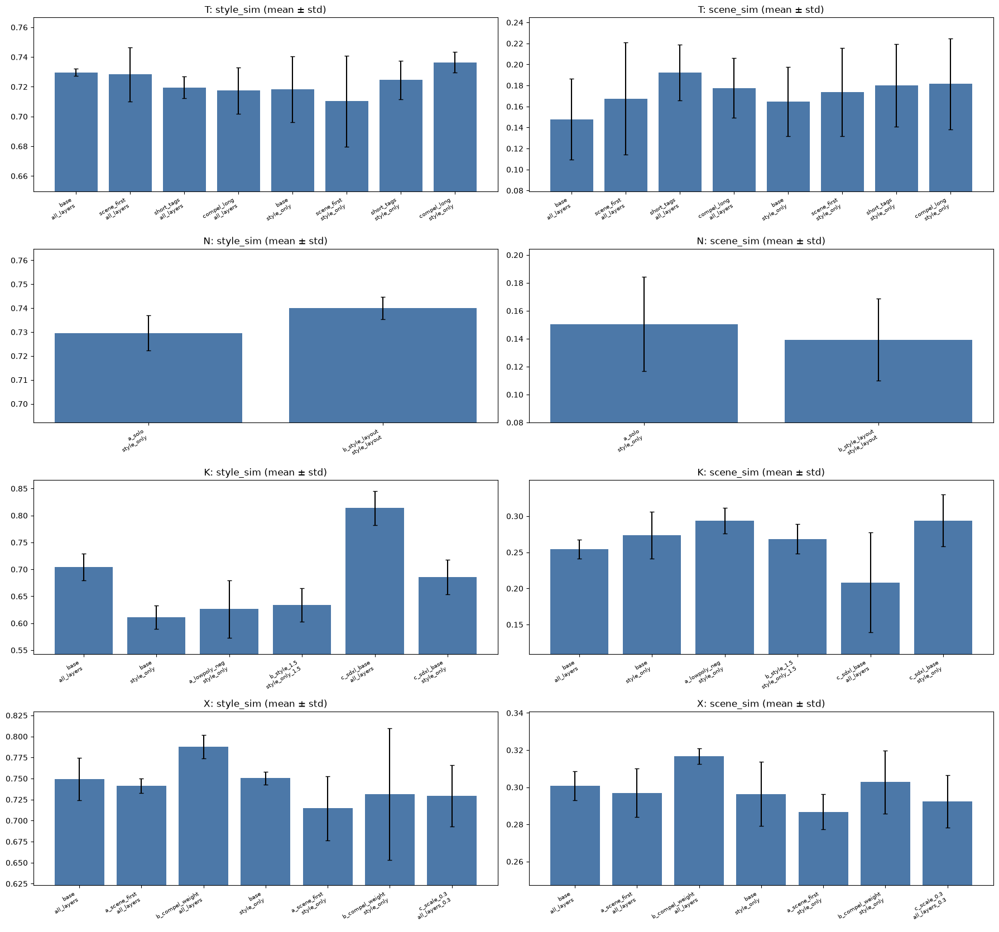

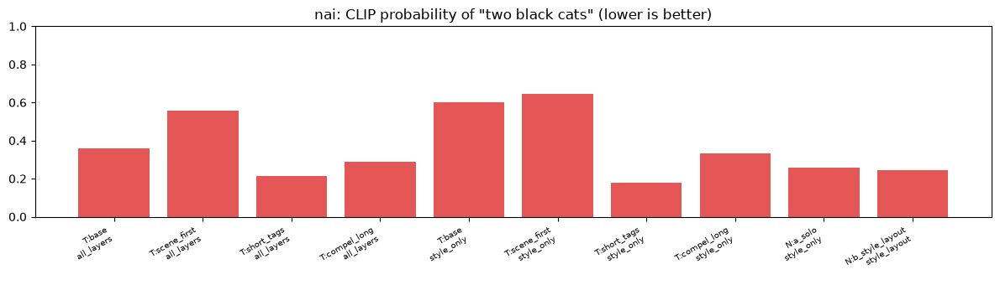

In [18]:
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


@torch.no_grad()
def embed_images(paths, bs=16):
    out = []
    for i in range(0, len(paths), bs):
        x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
        out.append(torch.nn.functional.normalize(feat(clip.get_image_features(**x)), dim=-1).float().cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def embed_texts(texts):
    t = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to('cuda')
    return torch.nn.functional.normalize(feat(clip.get_text_features(**t)), dim=-1).float().cpu().numpy()


GAME_FILES = {'nai': sorted((RAW / 'nai' / 'lora_gen').glob('*.png')),
              'kaykit': sorted((RAW / 'kaykit' / 'renders').glob('kk_*.png')),
              'x72': sorted((RAW / 'pixel_0x72' / 'scenes').glob('x72_scene_*.png'))}
rng = np.random.default_rng(0)
HELD = {}
for g, fs in GAME_FILES.items():
    pool = [p for p in fs if p.name != REFS[g].name]
    HELD[g] = embed_images([pool[i] for i in rng.choice(len(pool), 100, replace=False)])
SCENE_E = {it: e for it, e in zip(REQ1.index, embed_texts(list(REQ1.scene)))}
CAT_E = embed_texts(['a picture of one black cat', 'a picture of two black cats'])

exp = pd.read_csv(EXP_CSV, keep_default_na=False)
exp = exp[exp.error == ''].drop_duplicates('file', keep='last').reset_index(drop=True)
E = embed_images([FIX_DIR / f for f in exp.file])
exp['style_sim'] = [float((HELD[g] @ e).mean()) for e, g in zip(E, exp.game)]
exp['scene_sim'] = [float(SCENE_E[it] @ e) for e, it in zip(E, exp['item'])]
logits = 100 * E @ CAT_E.T
prob = np.exp(logits) / np.exp(logits).sum(1, keepdims=True)
exp['two_cat_prob'] = np.where(exp.game == 'nai', prob[:, 1], np.nan)
exp.to_csv(FIX_DIR / 'exp_scored.csv', index=False, encoding='utf-8-sig')
summ_fix = exp.groupby(['group', 'cond', 'mode'], sort=False).agg(
    n=('file', 'size'), style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'), scene_sim=('scene_sim', 'mean'),
    scene_std=('scene_sim', 'std'), two_cat_prob=('two_cat_prob', 'mean'), n_tokens=('n_tokens', 'max'),
    truncated=('truncated', 'mean'), gen_sec=('gen_sec', 'mean')).round(4)
summ_fix.to_csv(FIX_DIR / 'exp_summary.csv', encoding='utf-8-sig')
display(summ_fix)

groups = ['T', 'N', 'K', 'X']
fig, axes = plt.subplots(len(groups), 2, figsize=(18, 4.2 * len(groups)))
for r_, gname in enumerate(groups):
    s = summ_fix.loc[gname].reset_index()
    lab = [f'{c}\n{m}' for c, m in zip(s['cond'], s['mode'])]
    for c_, (col, std) in enumerate([('style_sim', 'style_std'), ('scene_sim', 'scene_std')]):
        ax = axes[r_, c_]
        ax.bar(np.arange(len(s)), s[col], yerr=s[std].fillna(0), capsize=3, color='#4C78A8')
        ax.set_xticks(np.arange(len(s)), lab, fontsize=7, rotation=30, ha='right')
        lo = (s[col] - s[std].fillna(0)).min()
        ax.set_ylim(max(0, lo - 0.03), (s[col] + s[std].fillna(0)).max() + 0.02)
        ax.set_title(f'{gname}: {col} (mean ± std)')
plt.tight_layout()
plt.savefig(FIX_DIR / 'exp_scores.png', dpi=80)
plt.show()

nai = summ_fix[summ_fix.two_cat_prob.notna()].reset_index()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(np.arange(len(nai)), nai.two_cat_prob, color='#E45756')
ax.set_xticks(np.arange(len(nai)), [f'{g}:{c}\n{m}' for g, c, m in zip(nai['group'], nai['cond'], nai['mode'])], fontsize=7, rotation=30, ha='right')
ax.set_ylim(0, 1)
ax.set_title('nai: CLIP probability of "two black cats" (lower is better)')
plt.tight_layout()
plt.savefig(FIX_DIR / 'exp_two_cat.png', dpi=80)
plt.show()

### 실험 그림 (seed 0)

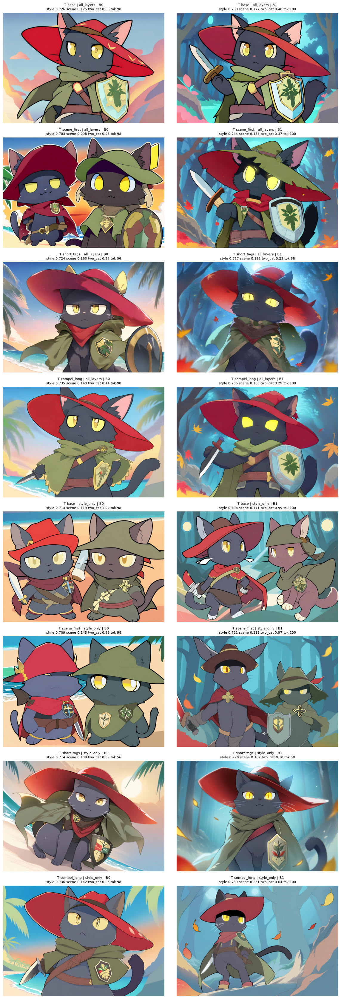

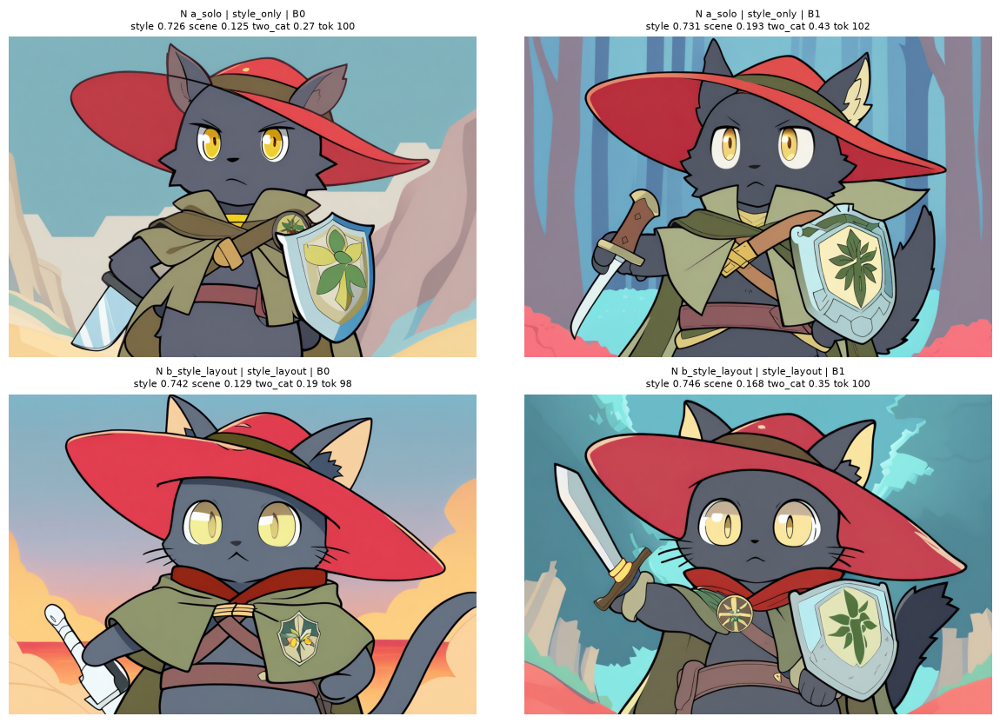

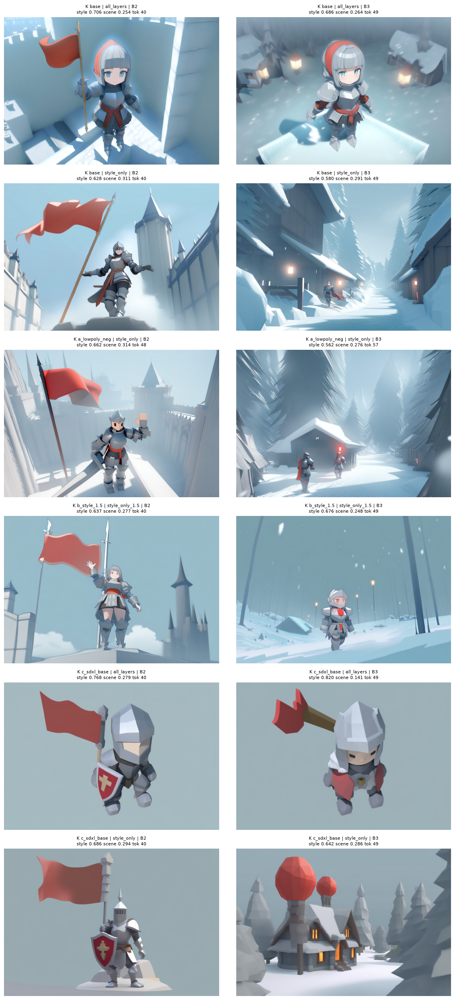

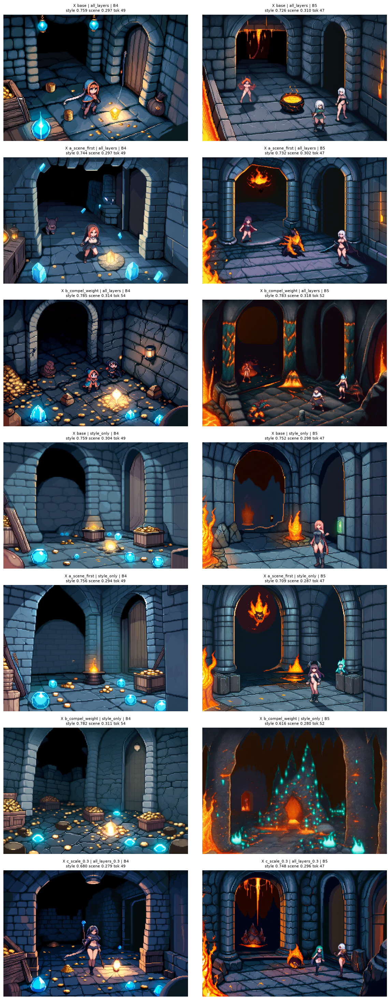

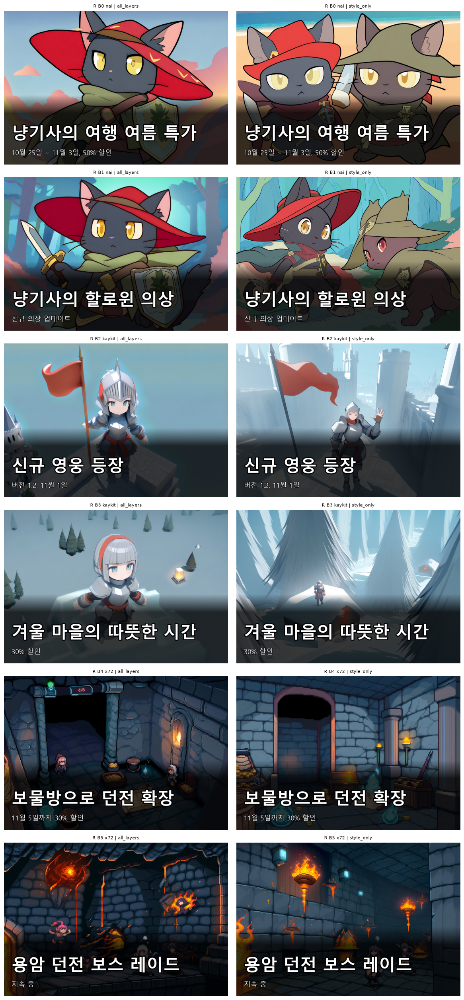

In [19]:
for gname in ['T', 'N', 'K', 'X']:
    sub_ = exp[(exp.group == gname) & (exp.seed == 0)]
    rows_ = list(dict.fromkeys(zip(sub_.cond, sub_['mode'])))
    cols_ = sorted(sub_['item'].unique())
    fig, axes = plt.subplots(len(rows_), len(cols_), figsize=(6 * len(cols_), 4.2 * len(rows_)), squeeze=False)
    for i, (c, m) in enumerate(rows_):
        for j, it in enumerate(cols_):
            ax = axes[i, j]
            r = sub_[(sub_.cond == c) & (sub_['mode'] == m) & (sub_['item'] == it)]
            if len(r):
                r = r.iloc[0]
                ax.imshow(Image.open(FIX_DIR / r.file))
                extra = f' two_cat {r.two_cat_prob:.2f}' if r.game == 'nai' else ''
                ax.set_title(f'{gname} {c} | {m} | {it}\nstyle {r.style_sim:.3f} scene {r.scene_sim:.3f}{extra} tok {r.n_tokens}', fontsize=8)
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(FIX_DIR / f'grid_{gname}.png', dpi=50)
    plt.show()

rbr = pd.read_csv(R_BANNER_CSV)
fig, axes = plt.subplots(len(rq), 2, figsize=(12, 4.2 * len(rq)), squeeze=False)
for i, r in enumerate(rq.itertuples()):
    for j, mode in enumerate(['all_layers', 'style_only']):
        f = FIX_DIR / f'R_{r.item}_{r.game}_{mode}.png'
        if f.exists():
            axes[i, j].imshow(Image.open(f))
        axes[i, j].set_title(f'R {r.item} {r.game} | {mode}', fontsize=8)
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig(FIX_DIR / 'grid_R.png', dpi=50)
plt.show()

## 채택 조합 + rating 태그, 판촉 표현 수정 후보 비교 (10/26)

위 "배너 문제 수정 실험" 결과로 게임별 수정안을 정했고(냥기사 (나) 태그 줄이기, KayKit (a) low poly 태그·부정 태그, 0x72 (b) Compel 가중치 + 전체 층), 남은 두 문제를 확인한다.

| 실험 | 문제 | 후보 |
|---|---|---|
| R2 | 판촉 규칙을 넣어도 B0 제목에 요청에 없는 "특가"가 남음(3번 생성 모두) | 현재(규칙 + (나) 후보 2개) / ① 그래도 실패하면 규칙 없는 첫 문구(v1)가 규칙을 통과할 때 v1을 씀 / ② 요청에 없는 금지어만 코드로 지움 / ③ (가) 방식: 실패 이유를 알려 주고 샘플링으로 다시 요청(최대 2번) |
| F | 0x72 일부 이미지에 노출이 많은 여성 캐릭터가 나옴. 프롬프트에 rating 태그가 없음 | 채택 조합 × rating 태그 없음 / `safe`(긍정) + `nsfw`(부정) |

- R2 후보 근거
  - 지시문 규칙 2에 금지어 목록(`BANNED_PROMO`)은 이미 적혀 있다(위 실험 설정 `INSTRUCTION_B2`). 그래서 "지시문에 금지어 목록을 적는 방식"은 현재 방식과 같아 따로 두지 않고, 대신 기능 A에서 비교했던 (가) 방식을 ③으로 둔다(08 "재생성 방식 비교").
  - 요청 6건에서는 실패가 1건뿐이라 후보 차이를 볼 수 없다. 그래서 게임마다 요청 4건을 더해 18건으로 비교한다. 새 요청의 절반은 할인율·날짜·버전이 있고 절반은 없어, 지어낸 숫자와 지어낸 판촉 표현이 모두 나올 수 있게 했다.
  - 기능 A 재생성 비교와 같이 seed 0·1·2로 돌린다. 규칙 없는 첫 문구(v1)와 규칙 적용 첫 문구는 탐욕적 디코딩이라 seed와 상관없이 한 번만 만든다.
  - ①은 실패했을 때만 v1을 만든다고 보고 시간에 v1 생성 시간을 더한다.
- F 근거
  - Animagine XL 4.0 모델 카드: rating 태그 `safe`·`sensitive`·`nsfw`·`explicit`로 "content safety level"을 조절한다. 태그 순서는 "1girl/1boy/1other, character, series, rating, everything else, quality tags"라 캐릭터·그림체 태그 뒤, 장면 태그 앞에 넣는다.
  - 냥기사는 IP-Adapter 방식(전체 층 / 그림체 블록)을 아직 정하지 않아 두 방식 모두 만든다.
  - rating 태그 없음 조건은 위 실험과 프롬프트·부정 프롬프트·seed가 같아 그 이미지를 그대로 쓰고(코드로 프롬프트가 같은지 확인), `safe` 조건 16장만 새로 만든다.
- 지표
  - R2: 규칙 위반 요청 비율(seed별), 위반 종류(판촉 표현·지어낸 숫자·빠진 숫자·형식), 생성 횟수, 시간, 후보별 최종 문구 표
  - F: 위 실험과 같은 CLIP `style_sim`, `scene_sim`, `two_cat_prob`(냥기사), 그리고 CLIP 제로샷 `exposed_prob`("revealing clothes with exposed skin" vs "modest clothes or armor"). CLIP 제로샷은 위 실험에서 고양이 수를 틀린 경우가 있어 seed 0·1 이미지를 모두 그림으로 함께 확인한다.
- 실행 순서: "설정" → "문구 합성 함수" → 위 "배너 문제 수정 실험"의 설정 셀(`23 conditions, 92 images`를 출력하는 셀) → 이 섹션. R2(Qwen)를 먼저 돌리고 배너 모델을 올린다(두 모델을 24GB에 함께 올릴 수 없음).

In [20]:
# R2: 기존 요청 6건 + 게임별 4건. 절반은 숫자(할인율·날짜·버전)가 있고 절반은 없음
R2_EXTRA = [
    ('nai', '벚꽃 핀 봄 언덕에서 냥기사 신규 스킨 공개 배너 만들어줘'),
    ('nai', '눈 오는 크리스마스 마을 배경으로 냥기사 겨울 업데이트 배너, 12월 20일 업데이트'),
    ('nai', '바다 위 배에서 냥기사 해적 의상 20% 할인 배너, 이번 주말까지'),
    ('nai', '도서관 배경으로 냥기사 스토리 2장 공개 배너'),
    ('kaykit', '숲속 야영지 배경으로 신규 캠프 콘텐츠 업데이트 배너'),
    ('kaykit', '사막 오아시스 배경으로 여름 시즌 패스 배너, 40% 할인, 8월 31일까지'),
    ('kaykit', '대장간 배경으로 무기 강화 시스템 추가 배너, 버전 1.3'),
    ('kaykit', '항구 마을 배경으로 신규 지역 오픈 배너 만들어줘'),
    ('x72', '얼음 동굴 배경으로 신규 던전 공개 배너'),
    ('x72', '지하 묘지 배경으로 할로윈 한정 던전 배너, 10월 31일까지'),
    ('x72', '마법 도서관 던전 배경으로 신규 직업 마법사 추가 배너'),
    ('x72', '거미 동굴 배경으로 난이도 하드 모드 추가 배너, 15% 할인'),
]
R2_REQUESTS = B_REQUESTS + R2_EXTRA
R2_SEEDS = [0, 1, 2]
# (가) 방식 재요청 횟수: 08 "재생성 방식 비교"와 같은 최대 2번
R2_MAX_EXTRA = 2
# 규칙 없는 첫 문구(v1): 위 "한국어 요청 → 배너"의 INSTRUCTION_B와 같은 지시문(규칙 1·2가 없음)
INSTRUCTION_V1 = INSTRUCTION_B2.replace(
    '규칙\n1. 요청에 있는 숫자(할인율·날짜·버전)는 글자 그대로 넣고, 요청에 없는 날짜·기간·가격·숫자는 지어내지 마.\n'
    '2. 요청에 없는 판촉 표현은 쓰지 마: {banned}\n', '')
assert '규칙' not in INSTRUCTION_V1 and '{banned}' not in INSTRUCTION_V1
R2_TASKS = [dict(item=f'B{i}', game=g, request=r, system=SYSTEM_B,
                 prompt=INSTRUCTION_B2.format(info=GAME_INFO[g], request=r, banned=', '.join(BANNED_PROMO)),
                 prompt_v1=INSTRUCTION_V1.format(info=GAME_INFO[g], request=r))
            for i, (g, r) in enumerate(R2_REQUESTS)]
R2_RAW_JSON = FIX_DIR / 'promo_fix_raw.json'
R2_CSV = FIX_DIR / 'promo_fix_records.csv'

# F: 채택 조합 × rating 태그. none은 위 실험 이미지를 그대로 씀(reuse: 위 실험 파일 이름 앞부분)
F_CSV = FIX_DIR / 'final_records.csv'
RATING = {'none': ('', ''), 'safe': ('safe, ', ', nsfw')}


def f_conds():
    out = []
    for rating, (pos, neg_add) in RATING.items():
        for mode, sc in [('all_layers', None), ('style_only', STYLE_ONLY)]:
            out.append(dict(name='nai_short_tags', rating=rating, items=['B0', 'B1'], mode=mode, sc=sc,
                            fn=lambda g, s, pos=pos: f'{NAI_SHORT}, {pos}{s}, {QUALITY}', neg=NEGATIVE + neg_add,
                            compel=False, reuse=f'T_short_tags_{mode}'))
        out.append(dict(name='kaykit_lowpoly_neg', rating=rating, items=['B2', 'B3'], mode='style_only', sc=STYLE_ONLY,
                        fn=lambda g, s, pos=pos: f'3d, low poly, render, {GAME_TAGS[g]}, {pos}{s}, {QUALITY}',
                        neg=NEGATIVE + ', anime, 1girl' + neg_add, compel=False, reuse='K_a_lowpoly_neg_style_only'))
        out.append(dict(name='x72_compel_weight', rating=rating, items=['B4', 'B5'], mode='all_layers', sc=None,
                        fn=lambda g, s, pos=pos: f'{GAME_TAGS[g]}, {pos}({s})1.3, {QUALITY}', neg=NEGATIVE + neg_add,
                        compel=True, reuse='X_b_compel_weight_all_layers'))
    return out


F_CONDS = f_conds()
print(len(R2_TASKS), 'R2 requests ×', len(R2_SEEDS), 'seeds |',
      sum(len(c['items']) * len(FIX_SEEDS) for c in F_CONDS if c['rating'] == 'safe'), 'new F images')

18 R2 requests × 3 seeds | 16 new F images


### R2. 판촉 표현 수정 후보 비교 (Qwen)

Qwen 로드 16.07초, 최대 VRAM 16.51GB | 규칙 적용 첫 문구 실패 1 / 18건, 규칙 없는 v1 실패 6건


C:\Users\Administrator\AppData\Local\Temp\ipykernel_16360\2428960643.py:146: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  'fail_rate': per_seed.mean(1), 'fail_std': per_seed.std(1),
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16360\2428960643.py:146: Pandas4Warning: Starting with pandas version 4.0 all arguments of std will be keyword-only.
  'fail_rate': per_seed.mean(1), 'fail_std': per_seed.std(1),


,fail_rate,fail_std,promo,made_up_number,missing_number,format,n_gen,sec
method,,,,,,,,
1_v1_fallback,0.000,0.0,0.0,0.0,0.0,0.0,1.167,4.955
2_strip_banned,0.000,0.0,0.0,0.0,0.0,0.0,1.111,4.691
3_feedback_sample,0.000,0.0,0.0,0.0,0.0,0.0,1.111,4.992
current,0.056,0.0,1.0,0.0,0.0,0.0,1.111,4.691


,item,request,seed,method,title,sub,problems,n_gen,sec
1,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,0,1_v1_fallback,냥기사의 여행 50% 할인,10월 25일 ~ 11월 3일,[],4,14.82
2,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,0,2_strip_banned,냥기사의 여행 여름,"10월 25일 ~ 11월 3일, 50% 할인",[],3,10.07
3,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,0,3_feedback_sample,냥기사의 여행 여름 할인,"10월 25일 ~ 11월 3일, 50% 할인",[],3,15.52
0,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,0,current,냥기사의 여행 여름 특가,"10월 25일 ~ 11월 3일, 50% 할인",[요청에 없는 판촉 표현을 썼다: 특가],3,10.07
5,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,1,1_v1_fallback,냥기사의 여행 50% 할인,10월 25일 ~ 11월 3일,[],4,14.82
6,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,1,2_strip_banned,냥기사의 여행 여름,"10월 25일 ~ 11월 3일, 50% 할인",[],3,10.07
7,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,1,3_feedback_sample,냥기사의 여행 여름 할인,"10월 25일 ~ 11월 3일, 50% 할인",[],3,15.47
4,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,1,current,냥기사의 여행 여름 특가,"10월 25일 ~ 11월 3일, 50% 할인",[요청에 없는 판촉 표현을 썼다: 특가],3,10.07
9,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,2,1_v1_fallback,냥기사의 여행 50% 할인,10월 25일 ~ 11월 3일,[],4,14.86
10,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,2,2_strip_banned,냥기사의 여행 여름,"10월 25일 ~ 11월 3일, 50% 할인",[],3,10.11


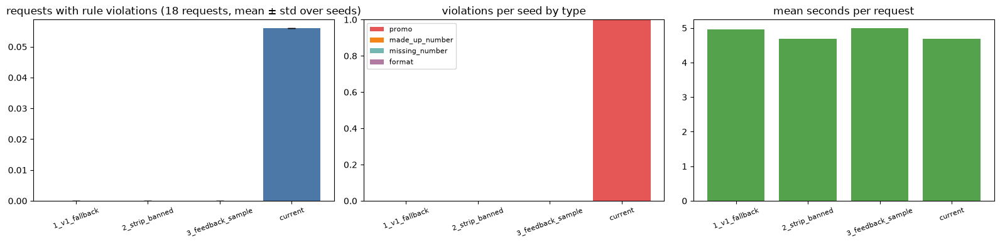

In [21]:
for _name in ['pipe', 'clip']:
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()

CHILD_R2 = r'''
import json, sys, time
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 2)
torch.cuda.reset_peak_memory_stats()
FB = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def msgs(t, prompt):
    return [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
            {'role': 'user', 'content': [{'type': 'text', 'text': prompt}]}]


def timed(f, *args, **kw):
    t1 = time.perf_counter()
    out = f(*args, **kw)
    return out, round(time.perf_counter() - t1, 2)


rows = []
for t in a['tasks']:
    r = dict(item=t['item'])
    (r['v1'],), r['v1_sec'] = timed(gen, msgs(t, t['prompt_v1']), False)
    (r['g0'],), r['g0_sec'] = timed(gen, msgs(t, t['prompt']), False)
    p0 = check_b(r['g0'], t['request'], a['banned'])
    r['seeds'] = []
    for s in a['seeds']:
        d = dict(seed=s)
        if p0:
            # 현재 방식 (나): 같은 입력으로 샘플링 후보 2개
            torch.manual_seed(s)
            d['cands'], d['cand_sec'] = timed(gen, msgs(t, t['prompt']), True, 2)
            # ③ (가): 실패 이유를 알려 주고 샘플링으로 다시 요청
            torch.manual_seed(s)
            m, final, probs, fb_texts, t1 = msgs(t, t['prompt']), r['g0'], p0, [], time.perf_counter()
            for k in range(a['max_extra']):
                m = m + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                         {'role': 'user', 'content': [{'type': 'text', 'text': FB + '\n'.join('- ' + x for x in probs)}]}]
                final = gen(m, True)[0]
                fb_texts.append(final)
                probs = check_b(final, t['request'], a['banned'])
                if not probs:
                    break
            d['fb_texts'], d['fb_sec'] = fb_texts, round(time.perf_counter() - t1, 2)
        r['seeds'].append(d)
    rows.append(r)
    print(t['item'], 'fail' if p0 else 'ok', flush=True)
print('RESULT' + json.dumps(dict(load_sec=load_sec, peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2),
                                 rows=rows), ensure_ascii=False), flush=True)
'''

p = subprocess.run([sys.executable, '-c', CHILD_R2],
                   input=json.dumps(dict(repo=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, tasks=R2_TASKS, validator=VALIDATOR_B,
                                         banned=BANNED_PROMO, seeds=R2_SEEDS, max_extra=R2_MAX_EXTRA)),
                   capture_output=True, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
if p.returncode != 0 or 'RESULT' not in p.stdout:
    print(p.stdout[-1500:], p.stderr[-3000:])
    raise RuntimeError('Qwen 단계 실패')
r2res = json.loads(p.stdout.split('RESULT', 1)[1].strip().splitlines()[0])
R2_RAW_JSON.write_text(json.dumps(r2res, ensure_ascii=False, indent=1), encoding='utf-8')


def probs_of(text, request):
    probs = check_b(text, request, BANNED_PROMO)
    d = parse_json(text)
    if d and isinstance(d.get('title'), str) and not d['title'].strip():
        probs.append('title이 비었다.')
    return probs


def strip_banned(text, request):
    # ②: 요청에 없는 금지어만 제목·부제에서 지우고 남은 공백·구두점을 정리
    d = parse_json(text)
    if not d:
        return text
    for k in ['title', 'sub']:
        v = d.get(k)
        if not isinstance(v, str):
            continue
        for w in BANNED_PROMO:
            if w not in request:
                v = v.replace(w, '')
        d[k] = re.sub(r'\s+', ' ', v).strip(' ,·!-~')
    return json.dumps(d, ensure_ascii=False)


def kinds(probs):
    out = []
    for x in probs:
        out.append('promo' if '판촉' in x else 'made_up_number' if '지어냈다' in x else 'missing_number' if '빠졌다' in x
                   else 'format')
    return out


recs = []
for t, r in zip(R2_TASKS, r2res['rows']):
    p0 = probs_of(r['g0'], t['request'])
    v1_probs = probs_of(r['v1'], t['request'])
    for d in r['seeds']:
        if not p0:
            base, base_n, base_sec = r['g0'], 1, r['g0_sec']
        else:
            best = min((len(probs_of(c, t['request'])), i, c) for i, c in enumerate(d['cands']))
            base = best[2] if best[0] < len(p0) else r['g0']
            base_n, base_sec = 3, r['g0_sec'] + d['cand_sec']
        bp = probs_of(base, t['request'])
        cand = {'current': (base, base_n, base_sec)}
        cand['1_v1_fallback'] = (r['v1'], base_n + 1, base_sec + r['v1_sec']) if bp and not v1_probs else (base, base_n, base_sec)
        cand['2_strip_banned'] = (strip_banned(base, t['request']), base_n, base_sec) if bp else (base, base_n, base_sec)
        cand['3_feedback_sample'] = ((d['fb_texts'][-1], 1 + len(d['fb_texts']), r['g0_sec'] + d['fb_sec']) if p0
                                     else (r['g0'], 1, r['g0_sec']))
        for method, (text, n_gen, sec) in cand.items():
            j = parse_json(text) or {}
            pr = probs_of(text, t['request'])
            recs.append(dict(item=t['item'], game=t['game'], request=t['request'], seed=d['seed'], method=method,
                             title=j.get('title', ''), sub=j.get('sub', ''), problems=pr, kinds=kinds(pr), fail=bool(pr),
                             n_gen=n_gen, sec=round(sec, 2), first_fail=bool(p0), v1_fail=bool(v1_probs), raw=text))
r2 = pd.DataFrame(recs)
r2.to_csv(R2_CSV, index=False, encoding='utf-8-sig')

per_seed = r2.groupby(['method', 'seed']).fail.mean().unstack()
r2_summary = pd.DataFrame({
    'fail_rate': per_seed.mean(1), 'fail_std': per_seed.std(1),
    **{k: r2.assign(x=r2.kinds.map(lambda ks, k=k: k in ks)).groupby('method').x.sum() / len(R2_SEEDS)
       for k in ['promo', 'made_up_number', 'missing_number', 'format']},
    'n_gen': r2.groupby('method').n_gen.mean(), 'sec': r2.groupby('method').sec.mean()}).round(3)
r2_summary.to_csv(FIX_DIR / 'promo_fix_summary.csv', encoding='utf-8-sig')
print(f"Qwen 로드 {r2res['load_sec']}초, 최대 VRAM {r2res['peak_vram_gb']}GB | 규칙 적용 첫 문구 실패 "
      f"{r2.drop_duplicates('item').first_fail.sum()} / {len(R2_TASKS)}건, 규칙 없는 v1 실패 {r2.drop_duplicates('item').v1_fail.sum()}건")
display(r2_summary)
pd.set_option('display.max_colwidth', 80)
fails = r2[r2.first_fail].sort_values(['item', 'seed', 'method'])
display(fails[['item', 'request', 'seed', 'method', 'title', 'sub', 'problems', 'n_gen', 'sec']])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
m = r2_summary.index
axes[0].bar(m, r2_summary.fail_rate, yerr=r2_summary.fail_std.fillna(0), capsize=4, color='#4C78A8')
axes[0].set_title(f'requests with rule violations ({len(R2_TASKS)} requests, mean ± std over seeds)')
kind_cols = ['promo', 'made_up_number', 'missing_number', 'format']
bottom = np.zeros(len(m))
for k, c in zip(kind_cols, ['#E45756', '#F58518', '#72B7B2', '#B279A2']):
    axes[1].bar(m, r2_summary[k], bottom=bottom, label=k, color=c)
    bottom += r2_summary[k].values
axes[1].legend(fontsize=8)
axes[1].set_title('violations per seed by type')
axes[2].bar(m, r2_summary.sec, color='#54A24B')
axes[2].set_title('mean seconds per request')
for ax in axes:
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
plt.tight_layout()
plt.savefig(FIX_DIR / 'promo_fix_scores.png', dpi=80)
plt.show()

### F. 채택 조합 + rating 태그 생성

In [22]:
from compel import CompelForSDXL
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

exp_prev = pd.read_csv(EXP_CSV, keep_default_na=False).drop_duplicates('file', keep='last').set_index('file')
pipe = StableDiffusionXLPipeline.from_pretrained(MODEL, torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(IPA['repo'], subfolder=IPA['subfolder'], weight_name=IPA['weight_name'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
compel = CompelForSDXL(pipe)

# 다시 실행하면 오류 없이 만든 이미지는 건너뛰고, 오류였던 것은 다시 만들어 기록을 바꿈
f_done = {x['file']: x for x in pd.read_csv(F_CSV, keep_default_na=False).to_dict('records')} if F_CSV.exists() else {}
for c in F_CONDS:
    for item in c['items']:
        g, scene = REQ1.loc[item, 'game'], REQ1.loc[item, 'scene']
        prompt = c['fn'](g, scene)
        sc = SCALE_ALL[g] if c['sc'] is None else c['sc']
        for s in FIX_SEEDS:
            rec = dict(name=c['name'], rating=c['rating'], mode=c['mode'], item=item, game=g, seed=s, prompt=prompt,
                       negative=c['neg'], ipa=json.dumps(sc), compel=c['compel'], error='')
            if c['rating'] == 'none':
                # 위 실험과 프롬프트·부정 프롬프트가 같은지 확인하고 그 이미지를 씀
                prev = exp_prev.loc[f"{c['reuse']}_{item}_s{s}.png"]
                assert prev.prompt == prompt and prev.negative == c['neg'], (prev.name, prompt)
                rec.update(file=prev.name, reused=True, gen_sec=float(prev.gen_sec))
            else:
                rec.update(file=f"F_{c['name']}_{c['rating']}_{c['mode']}_{item}_s{s}.png", reused=False)
                if rec['file'] in f_done and f_done[rec['file']]['error'] == '' and (FIX_DIR / rec['file']).exists():
                    continue
                pipe.set_ip_adapter_scale(sc)
                if c['compel']:
                    e = compel(prompt, negative_prompt=c['neg'])
                    kw = dict(prompt_embeds=e.embeds, pooled_prompt_embeds=e.pooled_embeds,
                              negative_prompt_embeds=e.negative_embeds, negative_pooled_prompt_embeds=e.negative_pooled_embeds)
                else:
                    kw = dict(prompt=prompt, negative_prompt=c['neg'])
                try:
                    t0 = time.perf_counter()
                    img = pipe(**kw, ip_adapter_image=Image.open(REFS[g]).convert('RGB'), width=W, height=H,
                               num_inference_steps=STEPS, guidance_scale=CFG, generator=torch.Generator('cpu').manual_seed(s)).images[0]
                    rec['gen_sec'] = round(time.perf_counter() - t0, 2)
                    img.save(FIX_DIR / rec['file'])
                except Exception as ex:
                    rec['error'] = f'{type(ex).__name__}: {ex}'[:300]
                print(rec['file'], rec.get('gen_sec'), rec['error'][:100], flush=True)
            f_done[rec['file']] = rec
            pd.DataFrame(list(f_done.values())).to_csv(F_CSV, index=False, encoding='utf-8')
fr = pd.read_csv(F_CSV, keep_default_na=False)
print('F', len(fr), '장 | 새로 생성', (fr.reused.astype(str) == 'False').sum(), '| 오류', (fr.error != '').sum())

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading weights: 100%|██████████| 776/776 [00:03<00:00, 209.03it/s]
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


F 32 장 | 새로 생성 16 | 오류 0


### F. 지표·그림 (seed 0·1)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 20635.80it/s]


n  style_sim  style_std  scene_sim  \
name               mode       rating                                       
nai_short_tags     all_layers none    4     0.7196     0.0073     0.1925   
                   style_only none    4     0.7245     0.0128     0.1801   
kaykit_lowpoly_neg style_only none    4     0.6264     0.0531     0.2935   
x72_compel_weight  all_layers none    4     0.7876     0.0140     0.3167   
nai_short_tags     all_layers safe    4     0.7130     0.0148     0.1870   
                   style_only safe    4     0.7132     0.0131     0.1867   
kaykit_lowpoly_neg style_only safe    4     0.6171     0.0485     0.2926   
x72_compel_weight  all_layers safe    4     0.7734     0.0210     0.3120   

                                      scene_std  two_cat_prob  exposed_prob  \
name               mode       rating                                          
nai_short_tags     all_layers none       0.0266        0.2139        0.9225   
                   style_only none       0.0391        0.1771        0.5767   
kaykit_lowpoly_neg style_only none       0.0177           NaN        0.1732   
x72_compel_weight  all_layers none       0.0041           NaN        0.7691   
nai_short_tags     all_layers safe       0.0277        0.1493        0.7168   
                   style_only safe       0.0203        0.1876        0.6482   
kaykit_lowpoly_neg style_only safe       0.0198           NaN        0.1861   
x72_compel_weight  all_layers safe       0.0068           NaN        0.5950   

                                      exposed_max  
name               mode       rating               
nai_short_tags     all_layers none         0.9506  
                   style_only none         0.7981  
kaykit_lowpoly_neg style_only none         0.2509  
x72_compel_weight  all_layers none         0.9313  
nai_short_tags     all_layers safe         0.8201  
                   style_only safe         0.9298  
kaykit_lowpoly_neg style_only safe         0.4058  
x72_compel_weight  all_layers safe         0.8201

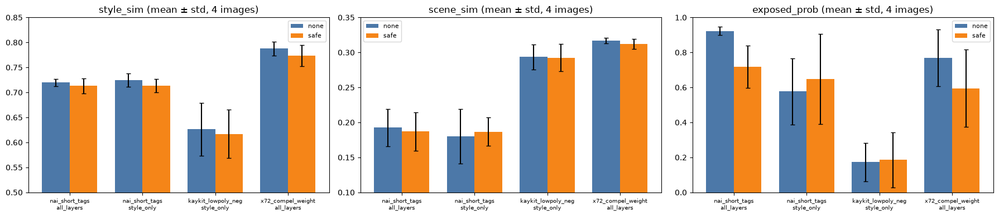

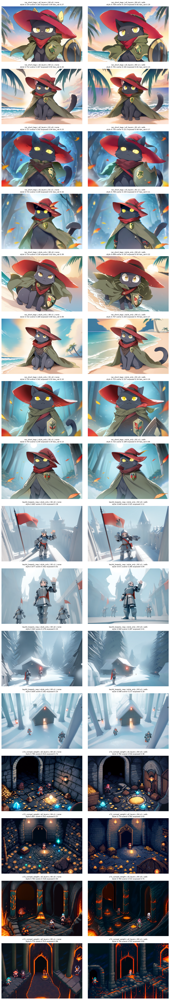

In [23]:
from transformers import CLIPModel, CLIPProcessor

for _name in ['pipe', 'compel', 'clip']:
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


@torch.no_grad()
def embed_images(paths, bs=16):
    out = []
    for i in range(0, len(paths), bs):
        x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
        out.append(torch.nn.functional.normalize(feat(clip.get_image_features(**x)), dim=-1).float().cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def embed_texts(texts):
    t = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to('cuda')
    return torch.nn.functional.normalize(feat(clip.get_text_features(**t)), dim=-1).float().cpu().numpy()


def zero_shot(E, texts):
    logits = 100 * E @ embed_texts(texts).T
    return (np.exp(logits) / np.exp(logits).sum(1, keepdims=True))[:, 1]


# 위 "실험 지표"와 같은 기준: 게임별 이미지 100장(참조 제외, seed 0 무작위), 장면 태그 문장
GAME_FILES = {'nai': sorted((RAW / 'nai' / 'lora_gen').glob('*.png')),
              'kaykit': sorted((RAW / 'kaykit' / 'renders').glob('kk_*.png')),
              'x72': sorted((RAW / 'pixel_0x72' / 'scenes').glob('x72_scene_*.png'))}
rng = np.random.default_rng(0)
HELD = {}
for g, fs in GAME_FILES.items():
    pool = [p for p in fs if p.name != REFS[g].name]
    HELD[g] = embed_images([pool[i] for i in rng.choice(len(pool), 100, replace=False)])
SCENE_E = {it: e for it, e in zip(REQ1.index, embed_texts(list(REQ1.scene)))}

fr = pd.read_csv(F_CSV, keep_default_na=False)
fr = fr[fr.error == ''].reset_index(drop=True)
E = embed_images([FIX_DIR / f for f in fr.file])
fr['style_sim'] = [float((HELD[g] @ e).mean()) for e, g in zip(E, fr.game)]
fr['scene_sim'] = [float(SCENE_E[it] @ e) for e, it in zip(E, fr['item'])]
fr['two_cat_prob'] = np.where(fr.game == 'nai', zero_shot(E, ['a picture of one black cat', 'a picture of two black cats']), np.nan)
fr['exposed_prob'] = zero_shot(E, ['a character wearing modest clothes or armor',
                                   'a character wearing revealing clothes with exposed skin'])
fr.to_csv(FIX_DIR / 'final_scored.csv', index=False, encoding='utf-8-sig')
f_summary = fr.groupby(['name', 'mode', 'rating'], sort=False).agg(
    n=('file', 'size'), style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'), scene_sim=('scene_sim', 'mean'),
    scene_std=('scene_sim', 'std'), two_cat_prob=('two_cat_prob', 'mean'), exposed_prob=('exposed_prob', 'mean'),
    exposed_max=('exposed_prob', 'max')).round(4)
f_summary.to_csv(FIX_DIR / 'final_summary.csv', encoding='utf-8-sig')
display(f_summary)

configs = list(dict.fromkeys(zip(fr['name'], fr['mode'])))
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
x = np.arange(len(configs))
for ax, col in zip(axes, ['style_sim', 'scene_sim', 'exposed_prob']):
    for k, (rating, color) in enumerate([('none', '#4C78A8'), ('safe', '#F58518')]):
        v = [fr[(fr['name'] == n) & (fr['mode'] == m) & (fr.rating == rating)][col] for n, m in configs]
        ax.bar(x + (k - 0.5) * 0.38, [s.mean() for s in v], 0.38, yerr=[s.std() for s in v], capsize=3, color=color, label=rating)
    ax.set_xticks(x, [f'{n}\n{m}' for n, m in configs], fontsize=7)
    ax.set_title(f'{col} (mean ± std, 4 images)')
    ax.legend(fontsize=8)
axes[0].set_ylim(0.5, 0.85)
axes[1].set_ylim(0.1, 0.35)
axes[2].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(FIX_DIR / 'final_scores.png', dpi=80)
plt.show()

# 그림: 행 = 조합·요청·seed, 열 = rating 없음 / safe
keys = list(dict.fromkeys(zip(fr['name'], fr['mode'], fr['item'], fr.seed)))
fig, axes = plt.subplots(len(keys), 2, figsize=(12, 4.2 * len(keys)), squeeze=False)
for i, (n, m, it, s) in enumerate(keys):
    for j, rating in enumerate(['none', 'safe']):
        ax = axes[i, j]
        r = fr[(fr['name'] == n) & (fr['mode'] == m) & (fr['item'] == it) & (fr.seed == s) & (fr.rating == rating)]
        if len(r):
            r = r.iloc[0]
            ax.imshow(Image.open(FIX_DIR / r.file))
            extra = f' two_cat {r.two_cat_prob:.2f}' if r.game == 'nai' else ''
            ax.set_title(f'{n} | {m} | {it} s{s} | {rating}\nstyle {r.style_sim:.3f} scene {r.scene_sim:.3f} '
                         f'exposed {r.exposed_prob:.2f}{extra}', fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.savefig(FIX_DIR / 'grid_F.png', dpi=50)
plt.show()

## 추가 확인: 실패 사례 늘리기(R3), 0x72 seed 늘리기(F2) (10/26)

위 R2·F는 문제 사례가 적어(R2 실패 1건, F 노출 캐릭터 1장) 후보 차이를 판단할 수 없었다. 사례를 늘려 다시 확인한다.

- R3 판촉 표현 후보: 후보는 R2와 같다(현재 / ① v1으로 되돌림 / ② 금지어 삭제 / ③ (가) 재요청).
  - (가) 실패하기 쉬운 요청 18건 추가(게임별 6건): R2 결과에서 규칙 없는 v1이 실패한 유형(요청에 없는 "특가"·"이벤트"·날짜)을 보고, 금지어를 직접 쓰지 않으면서 금지어를 부르기 쉬운 요청으로 만들었다. 세일·반값(→ 할인·특가), 공개일(→ 출시), 접속 보상·웰컴 패키지(→ 이벤트·무료·선물), 예약 판매(→ 사전예약), 반값·2배(→ 지어낸 숫자)
  - (나) seed 늘리기: R2 요청 18건과 새 18건 모두 seed 0~4(5개)로 돌린다. 첫 문구는 탐욕적 디코딩이라 seed를 늘려도 실패 건수는 그대로고, 실패한 요청에서 후보 생성·재요청 결과의 seed 간 차이를 본다.
  - 규칙 없는 v1과 규칙 적용 첫 문구는 탐욕적 디코딩이라, R2에서 만든 18건은 `promo_fix_raw.json`의 결과를 그대로 쓴다(R 셀을 두 번 실행했을 때 6건 문구가 같았음).
- F2 0x72 rating 태그: 채택 조합(Compel 가중치 + 전체 층) × rating 태그 없음 / `safe`를 seed 0~7(8개) × 요청 2개(B4·B5)로 비교한다. seed 0·1은 위 F 이미지를 그대로 쓰고 seed 2~7의 24장만 새로 만든다.
  - 노출 판정: 위 F에서 CLIP 제로샷 `exposed_prob`가 사람이 없는 고양이 이미지에서도 0.92로 나와 쓸 수 없었다. 그래서 32장 그림을 seed별로 나란히 그려 눈으로 센다. CLIP `style_sim`·`scene_sim`은 위와 같은 기준으로 함께 낸다.
- 실행 순서: "설정" → "문구 합성 함수" → "배너 문제 수정 실험"의 설정 셀 → 위 "채택 조합 + rating 태그" 섹션의 설정 셀(`18 R2 requests × 3 seeds`를 출력하는 셀) → 이 섹션. R3(Qwen)를 먼저 돌리고 배너 모델을 올린다.

In [24]:
R3_EXTRA = [
    ('nai', '봄 벚꽃 배경으로 냥기사 전 상품 40% 세일 배너, 4월 30일까지'),
    ('nai', '냥기사 신규 챕터가 12월 1일에 나와, 눈 덮인 숲 배경으로 배너'),
    ('nai', '추석 연휴 동안 냥기사 접속하면 보상 주는 배너, 한옥 마을 배경'),
    ('nai', '블랙 프라이데이 냥기사 반값 배너, 밤 도시 배경'),
    ('nai', '냥기사 아크릴 스탠드 굿즈 예약 판매 배너, 11월 20일부터'),
    ('nai', '냥기사 1주년 기념 배너, 축제 분위기 마을'),
    ('kaykit', '겨울 시즌 한정 패키지 35% 세일 배너, 설산 배경'),
    ('kaykit', '신규 영웅 팩 12월 10일 공개, 왕궁 홀 배경 배너'),
    ('kaykit', '주말 동안 경험치 2배 배너, 초원 배경'),
    ('kaykit', '크리스마스 맞이 스킨 반값 배너, 눈 내리는 광장'),
    ('kaykit', '신규 유저 웰컴 패키지 배너, 마을 입구 배경'),
    ('kaykit', '확장팩 예약 구매 배너, 1월 15일 오픈, 요새 배경'),
    ('x72', '던전 시즌 2 오픈 배너, 수정 동굴 배경, 25% 세일'),
    ('x72', '주말 동안 보스 아이템 2배 드롭 배너, 고대 사원 배경'),
    ('x72', '연말 반값 세일 배너, 횃불 복도 배경'),
    ('x72', '신규 던전 12월 24일 공개, 얼음 성채 배경'),
    ('x72', '출석 체크 7일 보상 배너, 지하 성 배경'),
    ('x72', '던전 OST 앨범 판매 시작 배너, 음악실 던전 배경'),
]
R3_REQUESTS = R2_REQUESTS + R3_EXTRA
R3_SEEDS = [0, 1, 2, 3, 4]
R3_TASKS = [dict(item=f'B{i}', game=g, request=r, system=SYSTEM_B, group='R2_18' if i < len(R2_REQUESTS) else 'new_18',
                 prompt=INSTRUCTION_B2.format(info=GAME_INFO[g], request=r, banned=', '.join(BANNED_PROMO)),
                 prompt_v1=INSTRUCTION_V1.format(info=GAME_INFO[g], request=r))
            for i, (g, r) in enumerate(R3_REQUESTS)]
# R2에서 만든 탐욕적 디코딩 결과(v1, 규칙 적용 첫 문구)를 그대로 씀
_r2raw = json.loads(R2_RAW_JSON.read_text(encoding='utf-8'))
R3_CACHE = {r['item']: {k: r[k] for k in ['v1', 'v1_sec', 'g0', 'g0_sec']} for r in _r2raw['rows']}
assert all(t['request'] == r for t, (g, r) in zip(R3_TASKS, R2_REQUESTS))
R3_RAW_JSON = FIX_DIR / 'promo_fix3_raw.json'
R3_CSV = FIX_DIR / 'promo_fix3_records.csv'

F2_SEEDS = list(range(8))
F2_CONDS = [c for c in F_CONDS if c['name'] == 'x72_compel_weight']
F2_CSV = FIX_DIR / 'final2_records.csv'
print(len(R3_TASKS), 'R3 requests (new', len(R3_EXTRA), ') ×', len(R3_SEEDS), 'seeds | F2',
      len(F2_CONDS) * 2 * len(F2_SEEDS), 'images (new', len(F2_CONDS) * 2 * (len(F2_SEEDS) - 2), ')')

36 R3 requests (new 18 ) × 5 seeds | F2 32 images (new 24 )


### R3. 판촉 표현 후보 (실패 사례 늘림, Qwen)

Qwen 로드 16.63초, 최대 VRAM 16.51GB, 전체 358.3초
R2_18: 규칙 적용 첫 문구 실패 1 / 18건, 규칙 없는 v1 실패 6건
new_18: 규칙 적용 첫 문구 실패 2 / 18건, 규칙 없는 v1 실패 3건
첫 문구가 실패한 요청에서 후보별로 끝까지 남은 실패 건수 (seed 평균)


,group,method,n_fail_requests,still_fail_mean,still_fail_std,promo,made_up_number,missing_number,format,n_gen,sec
0,R2_18,current,1,1.0,0.000,1.0,0.0,0.0,0.0,3.0,10.350
1,R2_18,1_v1_fallback,1,0.0,0.000,0.0,0.0,0.0,0.0,4.0,15.100
2,R2_18,2_strip_banned,1,0.0,0.000,0.0,0.0,0.0,0.0,3.0,10.350
3,R2_18,3_feedback_sample,1,0.0,0.000,0.0,0.0,0.0,0.0,3.0,15.706
4,new_18,current,2,1.6,0.548,1.6,0.0,0.0,0.0,3.0,8.425
5,new_18,1_v1_fallback,2,0.6,0.548,0.6,0.0,0.0,0.0,3.5,10.695
6,new_18,2_strip_banned,2,0.0,0.000,0.0,0.0,0.0,0.0,3.0,8.425
7,new_18,3_feedback_sample,2,0.0,0.000,0.0,0.0,0.0,0.0,2.0,8.040


,group,item,request,method,title,sub,problems,n_gen,sec
0,R2_18,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,current,냥기사의 여행 여름 특가,"10월 25일 ~ 11월 3일, 50% 할인",[요청에 없는 판촉 표현을 썼다: 특가],3,10.77
1,R2_18,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,1_v1_fallback,냥기사의 여행 50% 할인,10월 25일 ~ 11월 3일,[],4,15.52
2,R2_18,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,2_strip_banned,냥기사의 여행 여름,"10월 25일 ~ 11월 3일, 50% 할인",[],3,10.77
3,R2_18,B0,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,3_feedback_sample,냥기사의 여행 여름 할인,"10월 25일 ~ 11월 3일, 50% 할인",[],3,15.70
380,new_18,B19,"냥기사 신규 챕터가 12월 1일에 나와, 눈 덮인 숲 배경으로 배너",current,냥기사의 눈 덮인 여정,12월 1일 출시,[요청에 없는 판촉 표현을 썼다: 출시],3,8.80
381,new_18,B19,"냥기사 신규 챕터가 12월 1일에 나와, 눈 덮인 숲 배경으로 배너",1_v1_fallback,냥기사의 눈 덮인 여정,"12월 1일, 신규 챕터 개봉",[],4,13.34
382,new_18,B19,"냥기사 신규 챕터가 12월 1일에 나와, 눈 덮인 숲 배경으로 배너",2_strip_banned,냥기사의 눈 덮인 여정,12월 1일,[],3,8.80
383,new_18,B19,"냥기사 신규 챕터가 12월 1일에 나와, 눈 덮인 숲 배경으로 배너",3_feedback_sample,냥기사의 눈 덮인 여정,12월 1일,[],2,8.45
480,new_18,B24,"겨울 시즌 한정 패키지 35% 세일 배너, 설산 배경",current,겨울 시즌 한정 세일,35% 할인,[요청에 없는 판촉 표현을 썼다: 할인],3,7.73
481,new_18,B24,"겨울 시즌 한정 패키지 35% 세일 배너, 설산 배경",1_v1_fallback,겨울 시즌 한정 세일,35% 할인,[요청에 없는 판촉 표현을 썼다: 할인],3,7.73


seed 간 결과 차이: 후보·요청별 서로 다른 최종 문구 수


method,1_v1_fallback,2_strip_banned,3_feedback_sample,current
item,,,,
B0,1,1,1,1
B19,1,1,2,1
B24,3,3,1,3


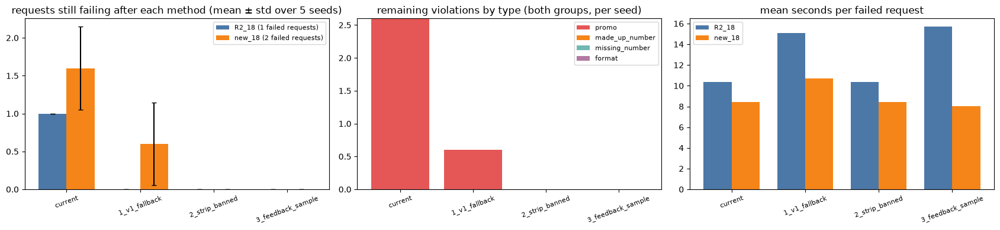

In [25]:
for _name in ['pipe', 'compel', 'clip']:
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()

CHILD_R3 = r'''
import json, sys, time
import torch
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 2)
torch.cuda.reset_peak_memory_stats()
FB = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def msgs(t, prompt):
    return [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
            {'role': 'user', 'content': [{'type': 'text', 'text': prompt}]}]


def timed(f, *args, **kw):
    t1 = time.perf_counter()
    out = f(*args, **kw)
    return out, round(time.perf_counter() - t1, 2)


rows = []
for t in a['tasks']:
    c = a['cache'].get(t['item'])
    if c:
        r = dict(item=t['item'], cached=True, **c)
    else:
        r = dict(item=t['item'], cached=False)
        (r['v1'],), r['v1_sec'] = timed(gen, msgs(t, t['prompt_v1']), False)
        (r['g0'],), r['g0_sec'] = timed(gen, msgs(t, t['prompt']), False)
    p0 = check_b(r['g0'], t['request'], a['banned'])
    r['seeds'] = []
    for s in a['seeds']:
        d = dict(seed=s)
        if p0:
            torch.manual_seed(s)
            d['cands'], d['cand_sec'] = timed(gen, msgs(t, t['prompt']), True, 2)
            torch.manual_seed(s)
            m, final, probs, fb_texts, t1 = msgs(t, t['prompt']), r['g0'], p0, [], time.perf_counter()
            for k in range(a['max_extra']):
                m = m + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                         {'role': 'user', 'content': [{'type': 'text', 'text': FB + '\n'.join('- ' + x for x in probs)}]}]
                final = gen(m, True)[0]
                fb_texts.append(final)
                probs = check_b(final, t['request'], a['banned'])
                if not probs:
                    break
            d['fb_texts'], d['fb_sec'] = fb_texts, round(time.perf_counter() - t1, 2)
        r['seeds'].append(d)
    rows.append(r)
    print(t['item'], 'fail' if p0 else 'ok', flush=True)
print('RESULT' + json.dumps(dict(load_sec=load_sec, peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2),
                                 rows=rows), ensure_ascii=False), flush=True)
'''

t_r3 = time.perf_counter()
p = subprocess.run([sys.executable, '-c', CHILD_R3],
                   input=json.dumps(dict(repo=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, tasks=R3_TASKS, validator=VALIDATOR_B,
                                         banned=BANNED_PROMO, seeds=R3_SEEDS, max_extra=R2_MAX_EXTRA, cache=R3_CACHE)),
                   capture_output=True, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
r3_total = round(time.perf_counter() - t_r3, 1)
if p.returncode != 0 or 'RESULT' not in p.stdout:
    print(p.stdout[-1500:], p.stderr[-3000:])
    raise RuntimeError('Qwen 단계 실패')
r3res = json.loads(p.stdout.split('RESULT', 1)[1].strip().splitlines()[0])
R3_RAW_JSON.write_text(json.dumps(r3res, ensure_ascii=False, indent=1), encoding='utf-8')


def probs_of(text, request):
    probs = check_b(text, request, BANNED_PROMO)
    d = parse_json(text)
    if d and isinstance(d.get('title'), str) and not d['title'].strip():
        probs.append('title이 비었다.')
    return probs


def strip_banned(text, request):
    # ②: 요청에 없는 금지어만 제목·부제에서 지우고 남은 공백·구두점을 정리
    d = parse_json(text)
    if not d:
        return text
    for k in ['title', 'sub']:
        v = d.get(k)
        if not isinstance(v, str):
            continue
        for w in BANNED_PROMO:
            if w not in request:
                v = v.replace(w, '')
        d[k] = re.sub(r'\s+', ' ', v).strip(' ,·!-~')
    return json.dumps(d, ensure_ascii=False)


def kinds(probs):
    return ['promo' if '판촉' in x else 'made_up_number' if '지어냈다' in x else 'missing_number' if '빠졌다' in x
            else 'format' for x in probs]


recs = []
for t, r in zip(R3_TASKS, r3res['rows']):
    p0 = probs_of(r['g0'], t['request'])
    v1_probs = probs_of(r['v1'], t['request'])
    for d in r['seeds']:
        if not p0:
            base, base_n, base_sec = r['g0'], 1, r['g0_sec']
        else:
            best = min((len(probs_of(c, t['request'])), i, c) for i, c in enumerate(d['cands']))
            base = best[2] if best[0] < len(p0) else r['g0']
            base_n, base_sec = 3, r['g0_sec'] + d['cand_sec']
        bp = probs_of(base, t['request'])
        cand = {'current': (base, base_n, base_sec)}
        cand['1_v1_fallback'] = (r['v1'], base_n + 1, base_sec + r['v1_sec']) if bp and not v1_probs else (base, base_n, base_sec)
        cand['2_strip_banned'] = (strip_banned(base, t['request']), base_n, base_sec) if bp else (base, base_n, base_sec)
        cand['3_feedback_sample'] = ((d['fb_texts'][-1], 1 + len(d['fb_texts']), r['g0_sec'] + d['fb_sec']) if p0
                                     else (r['g0'], 1, r['g0_sec']))
        for method, (text, n_gen, sec) in cand.items():
            j = parse_json(text) or {}
            pr = probs_of(text, t['request'])
            recs.append(dict(group=t['group'], item=t['item'], game=t['game'], request=t['request'], seed=d['seed'],
                             method=method, title=j.get('title', ''), sub=j.get('sub', ''), problems=pr, kinds=kinds(pr),
                             fail=bool(pr), n_gen=n_gen, sec=round(sec, 2), first_fail=bool(p0), first_problems=p0,
                             v1_fail=bool(v1_probs), raw=text))
r3 = pd.DataFrame(recs)
r3.to_csv(R3_CSV, index=False, encoding='utf-8-sig')

firsts = r3.drop_duplicates('item')
print(f"Qwen 로드 {r3res['load_sec']}초, 최대 VRAM {r3res['peak_vram_gb']}GB, 전체 {r3_total}초")
for grp, s in firsts.groupby('group', sort=False):
    print(f'{grp}: 규칙 적용 첫 문구 실패 {s.first_fail.sum()} / {len(s)}건, 규칙 없는 v1 실패 {s.v1_fail.sum()}건')
r3_fail = r3[r3.first_fail]
r3_summary = []
for (grp, method), s in r3_fail.groupby(['group', 'method'], sort=False):
    per_seed = s.groupby('seed').fail.sum()
    r3_summary.append(dict(group=grp, method=method, n_fail_requests=s['item'].nunique(),
                           still_fail_mean=per_seed.mean(), still_fail_std=per_seed.std(),
                           **{k: s.kinds.map(lambda ks, k=k: k in ks).sum() / len(R3_SEEDS)
                              for k in ['promo', 'made_up_number', 'missing_number', 'format']},
                           n_gen=s.n_gen.mean(), sec=s.sec.mean()))
r3_summary = pd.DataFrame(r3_summary).round(3)
r3_summary.to_csv(FIX_DIR / 'promo_fix3_summary.csv', index=False, encoding='utf-8-sig')
print('첫 문구가 실패한 요청에서 후보별로 끝까지 남은 실패 건수 (seed 평균)')
display(r3_summary)
pd.set_option('display.max_colwidth', 70)
display(r3_fail[r3_fail.seed == 0][['group', 'item', 'request', 'method', 'title', 'sub', 'problems', 'n_gen', 'sec']])
print('seed 간 결과 차이: 후보·요청별 서로 다른 최종 문구 수')
display(r3_fail.groupby(['method', 'item']).raw.nunique().unstack(0))

methods = list(dict.fromkeys(r3_summary.method))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for k, (grp, color) in enumerate([('R2_18', '#4C78A8'), ('new_18', '#F58518')]):
    s = r3_summary[r3_summary.group == grp].set_index('method').reindex(methods)
    x = np.arange(len(methods)) + (k - 0.5) * 0.38
    axes[0].bar(x, s.still_fail_mean, 0.38, yerr=s.still_fail_std.fillna(0), capsize=3, color=color,
                label=f'{grp} ({int(s.n_fail_requests.max()) if s.n_fail_requests.notna().any() else 0} failed requests)')
    axes[2].bar(x, s.sec, 0.38, color=color, label=grp)
s = r3_summary.groupby('method', sort=False)[['promo', 'made_up_number', 'missing_number', 'format']].sum().reindex(methods)
bottom = np.zeros(len(methods))
for kname, c in zip(s.columns, ['#E45756', '#F58518', '#72B7B2', '#B279A2']):
    axes[1].bar(methods, s[kname], bottom=bottom, label=kname, color=c)
    bottom += s[kname].values
axes[0].set_title('requests still failing after each method (mean ± std over 5 seeds)')
axes[1].set_title('remaining violations by type (both groups, per seed)')
axes[2].set_title('mean seconds per failed request')
for ax in axes:
    ax.set_xticks(np.arange(len(methods)), methods, rotation=20, fontsize=8)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIX_DIR / 'promo_fix3_scores.png', dpi=80)
plt.show()

### F2. 0x72 rating 태그 (seed 0~7)

In [26]:
from compel import CompelForSDXL
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

f_prev = pd.read_csv(F_CSV, keep_default_na=False).set_index('file')
pipe = StableDiffusionXLPipeline.from_pretrained(MODEL, torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(IPA['repo'], subfolder=IPA['subfolder'], weight_name=IPA['weight_name'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
compel = CompelForSDXL(pipe)

# 다시 실행하면 오류 없이 만든 이미지는 건너뛰고, 오류였던 것은 다시 만들어 기록을 바꿈
f2_done = {x['file']: x for x in pd.read_csv(F2_CSV, keep_default_na=False).to_dict('records')} if F2_CSV.exists() else {}
for c in F2_CONDS:
    for item in c['items']:
        g, scene = REQ1.loc[item, 'game'], REQ1.loc[item, 'scene']
        prompt = c['fn'](g, scene)
        sc = SCALE_ALL[g] if c['sc'] is None else c['sc']
        for s in F2_SEEDS:
            rec = dict(name=c['name'], rating=c['rating'], mode=c['mode'], item=item, game=g, seed=s, prompt=prompt,
                       negative=c['neg'], ipa=json.dumps(sc), compel=c['compel'], error='')
            old = f_prev[(f_prev['name'] == c['name']) & (f_prev.rating == c['rating']) & (f_prev['item'] == item)
                         & (f_prev.seed.astype(int) == s)]
            if len(old):
                # seed 0·1은 위 F 이미지를 그대로 씀 (프롬프트가 같은지 확인)
                assert old.iloc[0].prompt == prompt and old.iloc[0].negative == c['neg']
                rec.update(file=old.index[0], reused=True, gen_sec=float(old.iloc[0].gen_sec))
            else:
                rec.update(file=f"F2_{c['name']}_{c['rating']}_{c['mode']}_{item}_s{s}.png", reused=False)
                if rec['file'] in f2_done and f2_done[rec['file']]['error'] == '' and (FIX_DIR / rec['file']).exists():
                    continue
                pipe.set_ip_adapter_scale(sc)
                e = compel(prompt, negative_prompt=c['neg'])
                try:
                    t0 = time.perf_counter()
                    img = pipe(prompt_embeds=e.embeds, pooled_prompt_embeds=e.pooled_embeds,
                               negative_prompt_embeds=e.negative_embeds, negative_pooled_prompt_embeds=e.negative_pooled_embeds,
                               ip_adapter_image=Image.open(REFS[g]).convert('RGB'), width=W, height=H,
                               num_inference_steps=STEPS, guidance_scale=CFG, generator=torch.Generator('cpu').manual_seed(s)).images[0]
                    rec['gen_sec'] = round(time.perf_counter() - t0, 2)
                    img.save(FIX_DIR / rec['file'])
                except Exception as ex:
                    rec['error'] = f'{type(ex).__name__}: {ex}'[:300]
                print(rec['file'], rec.get('gen_sec'), rec['error'][:100], flush=True)
            f2_done[rec['file']] = rec
            pd.DataFrame(list(f2_done.values())).to_csv(F2_CSV, index=False, encoding='utf-8')
f2 = pd.read_csv(F2_CSV, keep_default_na=False)
print('F2', len(f2), '장 | 새로 생성', (f2.reused.astype(str) == 'False').sum(), '| 오류', (f2.error != '').sum())

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading weights: 100%|██████████| 776/776 [00:03<00:00, 205.46it/s]
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 28/28 [00:09<00:00,  2.90it/s]


F2_x72_compel_weight_none_all_layers_B4_s2.png 10.07 


100%|██████████| 28/28 [00:09<00:00,  2.81it/s]


F2_x72_compel_weight_none_all_layers_B4_s3.png 10.42 


100%|██████████| 28/28 [00:10<00:00,  2.78it/s]


F2_x72_compel_weight_none_all_layers_B4_s4.png 10.5 


... (38 outputs left out)

100%|██████████| 28/28 [00:10<00:00,  2.79it/s]


F2_x72_compel_weight_safe_all_layers_B5_s6.png 10.47 


100%|██████████| 28/28 [00:10<00:00,  2.78it/s]


F2_x72_compel_weight_safe_all_layers_B5_s7.png 10.5 
F2 32 장 | 새로 생성 24 | 오류 0


### F2. 지표·그림

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 21846.19it/s]


n  style_sim  style_std  scene_sim  scene_std
item rating                                               
B4   none    8     0.7848     0.0282     0.3044     0.0108
     safe    8     0.7748     0.0237     0.3062     0.0070
B5   none    8     0.7551     0.0300     0.3057     0.0138
     safe    8     0.7680     0.0297     0.3126     0.0112

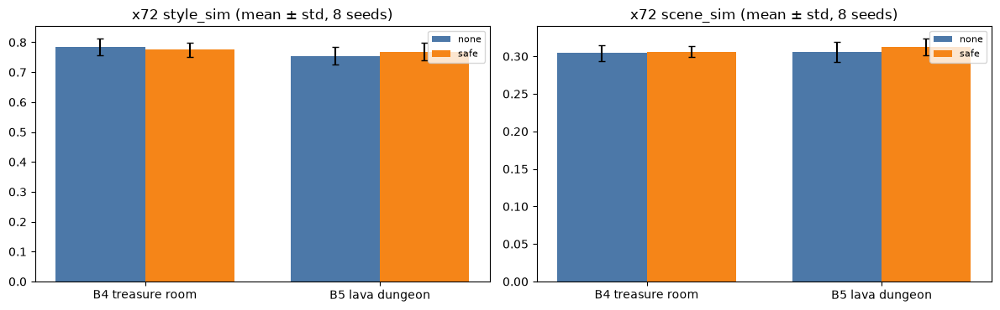

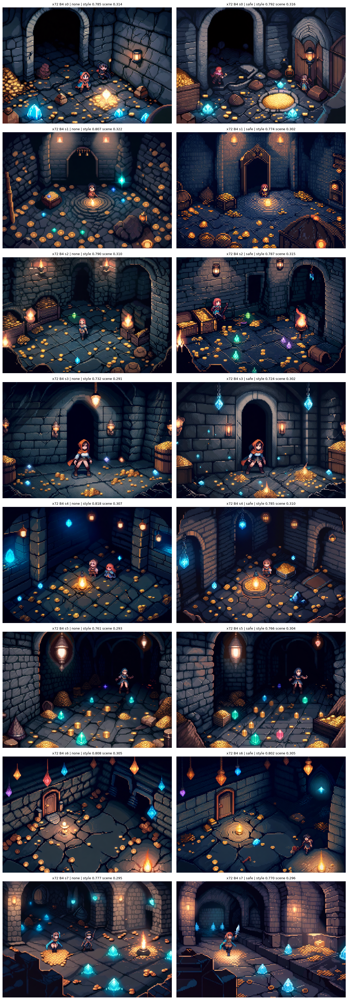

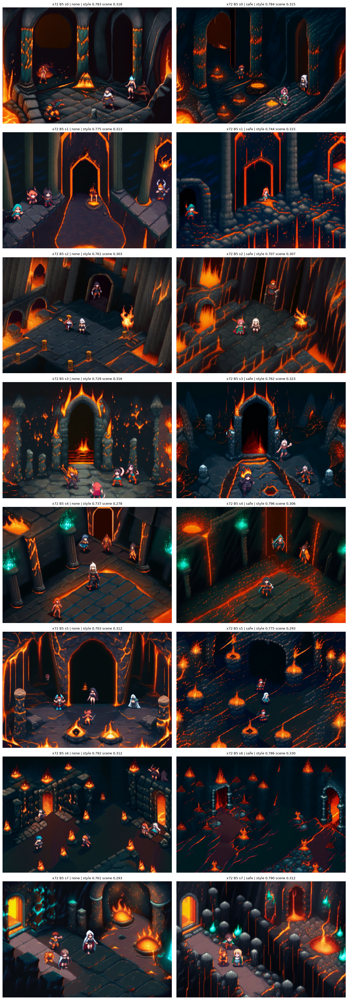

In [27]:
from transformers import CLIPModel, CLIPProcessor

for _name in ['pipe', 'compel']:
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()

# 위 "실험 지표"·"F. 지표·그림"과 같은 기준 (이 섹션만 따로 실행할 수 있게 다시 정의)
CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


@torch.no_grad()
def embed_images(paths, bs=16):
    out = []
    for i in range(0, len(paths), bs):
        x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
        out.append(torch.nn.functional.normalize(feat(clip.get_image_features(**x)), dim=-1).float().cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def embed_texts(texts):
    t = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to('cuda')
    return torch.nn.functional.normalize(feat(clip.get_text_features(**t)), dim=-1).float().cpu().numpy()


# 위와 같은 표본이 되도록 같은 순서(nai → kaykit → x72)로 무작위 추출하고 x72만 임베딩
GAME_FILES = {'nai': sorted((RAW / 'nai' / 'lora_gen').glob('*.png')),
              'kaykit': sorted((RAW / 'kaykit' / 'renders').glob('kk_*.png')),
              'x72': sorted((RAW / 'pixel_0x72' / 'scenes').glob('x72_scene_*.png'))}
rng = np.random.default_rng(0)
HELD = {}
for g, fs in GAME_FILES.items():
    pool = [p for p in fs if p.name != REFS[g].name]
    idx = rng.choice(len(pool), 100, replace=False)
    if g == 'x72':
        HELD[g] = embed_images([pool[i] for i in idx])
SCENE_E = {it: e for it, e in zip(REQ1.index, embed_texts(list(REQ1.scene)))}

f2 = pd.read_csv(F2_CSV, keep_default_na=False)
f2 = f2[f2.error == ''].reset_index(drop=True)
E2 = embed_images([FIX_DIR / f for f in f2.file])
f2['style_sim'] = [float((HELD[g] @ e).mean()) for e, g in zip(E2, f2.game)]
f2['scene_sim'] = [float(SCENE_E[it] @ e) for e, it in zip(E2, f2['item'])]
f2.to_csv(FIX_DIR / 'final2_scored.csv', index=False, encoding='utf-8-sig')
f2_summary = f2.groupby(['item', 'rating']).agg(n=('file', 'size'), style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'),
                                                scene_sim=('scene_sim', 'mean'), scene_std=('scene_sim', 'std')).round(4)
f2_summary.to_csv(FIX_DIR / 'final2_summary.csv', encoding='utf-8-sig')
display(f2_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ['style_sim', 'scene_sim']):
    for k, (rating, color) in enumerate([('none', '#4C78A8'), ('safe', '#F58518')]):
        v = [f2[(f2['item'] == it) & (f2.rating == rating)][col] for it in ['B4', 'B5']]
        ax.bar(np.arange(2) + (k - 0.5) * 0.38, [s.mean() for s in v], 0.38, yerr=[s.std() for s in v], capsize=3,
               color=color, label=rating)
    ax.set_xticks(np.arange(2), ['B4 treasure room', 'B5 lava dungeon'])
    ax.set_title(f'x72 {col} (mean ± std, 8 seeds)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIX_DIR / 'final2_scores.png', dpi=80)
plt.show()

# 그림: 요청별로 행 = seed, 열 = rating 없음 / safe (원본 1216×832를 크게 보이도록 요청마다 따로 저장)
for it in ['B4', 'B5']:
    fig, axes = plt.subplots(len(F2_SEEDS), 2, figsize=(14, 4.9 * len(F2_SEEDS)), squeeze=False)
    for i, s in enumerate(F2_SEEDS):
        for j, rating in enumerate(['none', 'safe']):
            ax = axes[i, j]
            r = f2[(f2['item'] == it) & (f2.seed == s) & (f2.rating == rating)]
            if len(r):
                r = r.iloc[0]
                ax.imshow(Image.open(FIX_DIR / r.file))
                ax.set_title(f'x72 {it} s{s} | {rating} | style {r.style_sim:.3f} scene {r.scene_sim:.3f}', fontsize=9)
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(FIX_DIR / f'grid_F2_{it}.png', dpi=60)
    plt.show()